In [15]:
# PAVEMENT TIME-TO-EVENT RESEARCH
# Notebook 01: LTPP Data Preparation
# Models: Weibull AFT, Cox PH and XGBoost Survival


# Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# Load the LTPP Dataset
file_path = r"C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\Bucket_143701.xlsx"
# Read the Excel file
df = pd.read_excel(file_path, sheet_name="ANALYSIS_IRI")
# Display the first five rows
df.head()


,STATE_CODE,STATE_CODE_EXP,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,RUN_NUMBER,IRI_LEFT_WHEEL_PATH,IRI_RIGHT_WHEEL_PATH,IRI_CENTER_LANE,...,IRI_LEFT_WHEEL_PATH_FLAG,IRI_LEFT_WHEEL_PATH_FLAG_EXP,IRI_RIGHT_WHEEL_PATH_FLAG,IRI_RIGHT_WHEEL_PATH_FLAG_EXP,IRI_CENTER_LANE_FLAG,IRI_CENTER_LANE_FLAG_EXP,MRI_FLAG,MRI_FLAG_EXP,PAVEMENT_FAMILY,PAVEMENT_FAMILY_EXP
0,1,Alabama,0101,1,1995-10-30,01010101,4,0.637,0.665,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
1,1,Alabama,0101,1,2002-03-10,01010114,2,0.678,0.700,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
2,1,Alabama,0101,1,2002-03-10,01010114,7,0.701,0.731,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
3,1,Alabama,0101,1,2002-03-10,01010114,5,0.652,0.646,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
4,1,Alabama,0101,1,2002-03-10,01010114,3,0.707,0.793,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade


In [16]:

# LoadING THE IRI Data
iri_df = pd.read_excel(file_path, sheet_name="ANALYSIS_IRI")

# Loading Rutting Data
rutting_df = pd.read_excel(file_path, sheet_name="ANALYSIS_RUTTING")

# Load Construction Data
construction_df = pd.read_excel(file_path, sheet_name="EXPERIMENT_SECTION")

# dataset dimensions
print("IRI Dataset:", iri_df.shape)
print("Rutting Dataset:", rutting_df.shape)
print("Construction Dataset:", construction_df.shape)


IRI Dataset: (154765, 21)
Rutting Dataset: (21527, 39)
Construction Dataset: (7934, 25)


In [17]:

# DisplayING the first five rows of each dataset

print("IRI Data")
display(iri_df.head())

print("Rutting Data")
display(rutting_df.head())

print("Construction Data")
display(construction_df.head())


IRI Data


,STATE_CODE,STATE_CODE_EXP,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,RUN_NUMBER,IRI_LEFT_WHEEL_PATH,IRI_RIGHT_WHEEL_PATH,IRI_CENTER_LANE,...,IRI_LEFT_WHEEL_PATH_FLAG,IRI_LEFT_WHEEL_PATH_FLAG_EXP,IRI_RIGHT_WHEEL_PATH_FLAG,IRI_RIGHT_WHEEL_PATH_FLAG_EXP,IRI_CENTER_LANE_FLAG,IRI_CENTER_LANE_FLAG_EXP,MRI_FLAG,MRI_FLAG_EXP,PAVEMENT_FAMILY,PAVEMENT_FAMILY_EXP
0,1,Alabama,0101,1,1995-10-30,01010101,4,0.637,0.665,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
1,1,Alabama,0101,1,2002-03-10,01010114,2,0.678,0.700,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
2,1,Alabama,0101,1,2002-03-10,01010114,7,0.701,0.731,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
3,1,Alabama,0101,1,2002-03-10,01010114,5,0.652,0.646,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
4,1,Alabama,0101,1,2002-03-10,01010114,3,0.707,0.793,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade


Rutting Data


,STATE_CODE,STATE_CODE_EXP,SHRP_ID,CONSTRUCTION_NO,VISIT_NO,RUN_NUMBER,SURVEY_DATE,T_PROF_DEVICE_CODE,T_PROF_DEVICE_CODE_EXP,NO_PROFILES,...,MAX_MEAN_DEPTH_1_8_FLAG_EXP,MAX_MEAN_DEPTH_1_8_FLAG,LLH_DEPTH_WIRE_REF_MEAN_FLAG,LLH_DEPTH_WIRE_REF_MEAN_FLAG_EXP,RLH_DEPTH_WIRE_REF_MEAN_FLAG,RLH_DEPTH_WIRE_REF_MEAN_FLAG_EXP,MAX_MEAN_DEPTH_WIRE_REF_FLAG,MAX_MEAN_DEPTH_WIRE_REF_FLAG_EXP,PAVEMENT_FAMILY,PAVEMENT_FAMILY_EXP
0,1,Alabama,0101,1,01010109,1,1998-04-25,D,Dipstick,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
1,1,Alabama,0101,1,01010107,1,1996-10-10,D,Dipstick,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
2,1,Alabama,0101,1,01010111,1,2000-02-05,P,Pasco,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
3,1,Alabama,0101,1,01010114,1,2001-08-23,D,Dipstick,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade
4,1,Alabama,0101,1,01010105,1,1996-01-10,P,Pasco,10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ACUB,Asphalt concrete over unbound base/subgrade


Construction Data


,STATE_CODE,STATE_CODE_EXP,SHRP_ID,CONSTRUCTION_NO,CN_ASSIGN_DATE,CN_CHANGE_REASON,CN_CHANGE_REASON_EXP,RECORD_STATUS,GPS_SPS,GPS_SPS_EXP,...,DEASSIGN_DATE,SEAS_ID,SUPPLEMENTAL,EXP_SECT_RS,BASIC_INFO_RS,PAV_STRUCT_RS,TRAFFIC_RS,CLIMATIC_RS,PAVEMENT_FAMILY,PAVEMENT_FAMILY_EXP
0,1,Alabama,0100,1,1991-04-30,NaN,NaN,E,S,Specific Pavement Studies,...,2005-06-15,NaN,NaN,E,E,NaN,E,E,NaN,NaN
1,1,Alabama,0101,1,1991-04-30,NaN,NaN,E,S,Specific Pavement Studies,...,2005-06-15,A,NaN,E,E,E,E,E,ACUB,Asphalt concrete over unbound base/subgrade
2,1,Alabama,0102,1,1991-04-30,NaN,NaN,E,S,Specific Pavement Studies,...,2005-06-15,B,NaN,E,E,E,E,E,ACUB,Asphalt concrete over unbound base/subgrade
3,1,Alabama,0102,2,2003-04-17,"24,27",Full Depth Patch of AC Pavement (removing dama...,E,S,Specific Pavement Studies,...,2005-06-15,NaN,NaN,E,E,E,E,E,ACUB,Asphalt concrete over unbound base/subgrade
4,1,Alabama,0103,1,1991-04-30,NaN,NaN,E,S,Specific Pavement Studies,...,2005-06-15,NaN,NaN,E,E,E,E,E,ACTB,Asphalt concrete over cement/lime treated base...


In [23]:
# 2.1 DATASET STRUCTURE
# Examining IRI dataset
print("IRI DATASET")
print("Shape:", iri_df.shape)
iri_df.info()

# Examining Rutting dataset
print("\nRUTTING DATASET")
print("Shape:", rutting_df.shape)
rutting_df.info()

# Examining Construction dataset
print("\nCONSTRUCTION DATASET")
print("Shape:", construction_df.shape)
construction_df.info()


IRI DATASET
Shape: (154765, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 154765 entries, 0 to 154764
Data columns (total 21 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   STATE_CODE                     154765 non-null  int64         
 1   STATE_CODE_EXP                 154765 non-null  object        
 2   SHRP_ID                        154765 non-null  object        
 3   CONSTRUCTION_NO                154765 non-null  int64         
 4   VISIT_DATE                     154765 non-null  datetime64[ns]
 5   VISIT_NO                       154765 non-null  object        
 6   RUN_NUMBER                     154765 non-null  int64         
 7   IRI_LEFT_WHEEL_PATH            154763 non-null  float64       
 8   IRI_RIGHT_WHEEL_PATH           154765 non-null  float64       
 9   IRI_CENTER_LANE                22297 non-null   float64       
 10  MRI                            15476

In [26]:
# 2.2 MISSING VALUES

# Calculate missing values for each dataset
iri_missing = iri_df.isnull().sum()
rutting_missing = rutting_df.isnull().sum()
construction_missing = construction_df.isnull().sum()

# Calculate the percentage of missing values
iri_missing_pct = (iri_missing / len(iri_df)) * 100
rutting_missing_pct = (rutting_missing / len(rutting_df)) * 100
construction_missing_pct = (
    construction_missing / len(construction_df)
) * 100

# Creating missing value summary tables
iri_missing_summary = pd.DataFrame({
    "Missing Values": iri_missing,
    "Percentage (%)": iri_missing_pct
})

rutting_missing_summary = pd.DataFrame({
    "Missing Values": rutting_missing,
    "Percentage (%)": rutting_missing_pct
})

construction_missing_summary = pd.DataFrame({
    "Missing Values": construction_missing,
    "Percentage (%)": construction_missing_pct
})

# missing values
print("IRI Missing Values")
display(iri_missing_summary.sort_values(
    by="Percentage (%)", ascending=False
))

print("Rutting Missing Values")
display(rutting_missing_summary.sort_values(
    by="Percentage (%)", ascending=False
))

print("Construction Missing Values")
display(construction_missing_summary.sort_values(
    by="Percentage (%)", ascending=False
))


IRI Missing Values


,Missing Values,Percentage (%)
IRI_CENTER_LANE_FLAG_EXP,153631,99.267276
IRI_CENTER_LANE_FLAG,153631,99.267276
MRI_FLAG_EXP,144080,93.095984
MRI_FLAG,144080,93.095984
IRI_LEFT_WHEEL_PATH_FLAG_EXP,142923,92.348399
IRI_LEFT_WHEEL_PATH_FLAG,142923,92.348399
IRI_RIGHT_WHEEL_PATH_FLAG_EXP,142313,91.954253
IRI_RIGHT_WHEEL_PATH_FLAG,142313,91.954253
IRI_CENTER_LANE,132468,85.592996
MRI,2,0.001292


Rutting Missing Values


,Missing Values,Percentage (%)
RLH_DEPTH_1_8_MEAN_FLAG_EXP,21479,99.777024
RLH_DEPTH_1_8_MEAN_FLAG,21479,99.777024
MAX_MEAN_DEPTH_1_8_FLAG_EXP,21467,99.721280
MAX_MEAN_DEPTH_1_8_FLAG,21467,99.721280
LLH_DEPTH_1_8_MEAN_FLAG,21458,99.679472
LLH_DEPTH_1_8_MEAN_FLAG_EXP,21458,99.679472
RLH_DEPTH_WIRE_REF_MEAN_FLAG_EXP,21438,99.586566
RLH_DEPTH_WIRE_REF_MEAN_FLAG,21438,99.586566
MAX_MEAN_DEPTH_WIRE_REF_FLAG,21416,99.484368
MAX_MEAN_DEPTH_WIRE_REF_FLAG_EXP,21416,99.484368


Construction Missing Values


,Missing Values,Percentage (%)
SEAS_ID,7731,97.441391
SUPPLEMENTAL,6559,82.669524
CN_CHANGE_REASON_EXP,2840,35.795311
CN_CHANGE_REASON,2829,35.656668
STATUS_EXP,952,11.998992
STATUS,952,11.998992
DEASSIGN_DATE,787,9.919335
TRAFFIC_RS,369,4.650870
PAVEMENT_FAMILY,274,3.453491
PAVEMENT_FAMILY_EXP,274,3.453491


In [27]:
# 2.3 DUPLICATE RECORDS

# Identify exact duplicate rows
iri_duplicates = iri_df.duplicated().sum()
rutting_duplicates = rutting_df.duplicated().sum()
construction_duplicates = construction_df.duplicated().sum()

print("Exact Duplicate Records")
print("IRI:", iri_duplicates)
print("Rutting:", rutting_duplicates)
print("Construction:", construction_duplicates)

# Check repeated measurements for the same section and date
iri_repeated = iri_df.duplicated(
    subset=[
        "STATE_CODE", "SHRP_ID",
        "CONSTRUCTION_NO", "VISIT_DATE"
    ],
    keep=False
).sum()

rutting_repeated = rutting_df.duplicated(
    subset=[
        "STATE_CODE", "SHRP_ID",
        "CONSTRUCTION_NO", "SURVEY_DATE"
    ],
    keep=False
).sum()

print("\nRecords Sharing the Same Section and Survey Date")
print("IRI:", iri_repeated)
print("Rutting:", rutting_repeated)


Exact Duplicate Records
IRI: 14
Rutting: 0
Construction: 0

Records Sharing the Same Section and Survey Date
IRI: 154620
Rutting: 108


In [28]:
# 2.4 IRI AND RUTTING MEASUREMENT SUMMARY

# Select the principal measurement columns
iri_columns = [
    "IRI_LEFT_WHEEL_PATH",
    "IRI_RIGHT_WHEEL_PATH",
    "MRI"
]

rutting_columns = [
    "MAX_MEAN_DEPTH_1_8",
    "MAX_MEAN_DEPTH_WIRE_REF"
]

# Descriptive statistics
print("IRI Measurement Summary")
display(iri_df[iri_columns].describe())

print("\nRutting Measurement Summary")
display(rutting_df[rutting_columns].describe())

# Check negative measurement values
print("\nNegative Measurement Values")

for column in iri_columns:
    values = pd.to_numeric(iri_df[column], errors="coerce")
    print(column, ":", (values < 0).sum())

for column in rutting_columns:
    values = pd.to_numeric(rutting_df[column], errors="coerce")
    print(column, ":", (values < 0).sum())


IRI Measurement Summary


,IRI_LEFT_WHEEL_PATH,IRI_RIGHT_WHEEL_PATH,MRI
count,154763.000000,154765.000000,154763.000000
mean,1.389284,1.446351,1.417819
std,0.619237,0.669868,0.624065
min,0.294000,0.323000,0.317000
25%,0.957000,0.983000,0.984000
50%,1.260000,1.309000,1.290000
75%,1.678000,1.727000,1.703000
max,6.781000,9.778000,6.009000



Rutting Measurement Summary


,MAX_MEAN_DEPTH_1_8,MAX_MEAN_DEPTH_WIRE_REF
count,21527.000000,21527.000000
mean,5.250476,5.852046
std,3.477589,3.790332
min,0.000000,0.000000
25%,3.000000,3.000000
50%,4.000000,5.000000
75%,7.000000,7.000000
max,34.000000,36.000000



Negative Measurement Values
IRI_LEFT_WHEEL_PATH : 0
IRI_RIGHT_WHEEL_PATH : 0
MRI : 0
MAX_MEAN_DEPTH_1_8 : 0
MAX_MEAN_DEPTH_WIRE_REF : 0


In [29]:
# 2.5 MEASUREMENT QUALITY FLAGS

# IRI quality flags
print("IRI Measurement Flags")

display(
    iri_df["MRI_FLAG_EXP"].value_counts(
        dropna=False
    )
)

# Rutting quality flags
print("\nRutting Measurement Flags")

display(
    rutting_df["MAX_MEAN_DEPTH_1_8_FLAG_EXP"].value_counts(
        dropna=False
    )
)

# Rutting measurement devices
print("\nRutting Measurement Devices")

display(
    rutting_df["T_PROF_DEVICE_CODE_EXP"].value_counts(
        dropna=False
    )
)


IRI Measurement Flags


MRI_FLAG_EXP
NaN                  144080
Unexplained trend     10685
Name: count, dtype: int64


Rutting Measurement Flags


MAX_MEAN_DEPTH_1_8_FLAG_EXP
NaN                  21467
Unexplained trend       60
Name: count, dtype: int64


Rutting Measurement Devices


T_PROF_DEVICE_CODE_EXP
Dipstick    11001
Pasco        9514
Laser        1012
Name: count, dtype: int64

In [30]:
# 2.6 INVESTIGATE REPEATED MEASUREMENTS

# Pavement section identifiers
section_cols = [
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO"
]

# Group IRI measurements by pavement section and visit date
iri_visits = iri_df.groupby(
    section_cols + ["VISIT_DATE"],
    dropna=False
).agg(
    Number_of_Runs=("RUN_NUMBER", "size"),
    Unique_Runs=("RUN_NUMBER", "nunique"),
    Minimum_MRI=("MRI", "min"),
    Maximum_MRI=("MRI", "max"),
    Flagged_Runs=("MRI_FLAG", "count")
).reset_index()

# Calculate the variation between runs
iri_visits["MRI_Range"] = (
    iri_visits["Maximum_MRI"] -
    iri_visits["Minimum_MRI"]
)

# Display IRI inspection summary
print("IRI INSPECTION SUMMARY")
print("Total records:", len(iri_df))
print("Unique inspection dates:", len(iri_visits))
print(
    "Inspections with multiple runs:",
    (iri_visits["Number_of_Runs"] > 1).sum()
)

display(
    iri_visits.sort_values(
        "MRI_Range",
        ascending=False
    ).head(10)
)

# Group rutting measurements by section and survey date
rutting_visits = rutting_df.groupby(
    section_cols + ["SURVEY_DATE"],
    dropna=False
).agg(
    Number_of_Runs=("RUN_NUMBER", "size"),
    Unique_Devices=("T_PROF_DEVICE_CODE", "nunique"),
    Minimum_Rut=("MAX_MEAN_DEPTH_1_8", "min"),
    Maximum_Rut=("MAX_MEAN_DEPTH_1_8", "max")
).reset_index()

print("\nRUTTING INSPECTION SUMMARY")
print("Total records:", len(rutting_df))
print("Unique inspection dates:", len(rutting_visits))
print(
    "Inspections with multiple runs:",
    (rutting_visits["Number_of_Runs"] > 1).sum()
)

display(
    rutting_visits[
        rutting_visits["Number_of_Runs"] > 1
    ].head(10)
)


IRI INSPECTION SUMMARY
Total records: 154765
Unique inspection dates: 30215
Inspections with multiple runs: 30070


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,Number_of_Runs,Unique_Runs,Minimum_MRI,Maximum_MRI,Flagged_Runs,MRI_Range
2845,5,0217,4,2013-06-21,15,7,2.119,5.665,0,3.546
910,4,0213,4,2019-05-15,10,5,2.466,4.404,0,1.938
2843,5,0217,4,2012-01-19,5,5,2.782,4.330,0,1.548
907,4,0213,3,2016-12-20,5,5,1.930,3.373,0,1.443
13352,27,3009,4,2018-09-26,5,5,2.424,3.710,0,1.286
911,4,0213,4,2019-05-16,10,7,2.708,3.988,10,1.280
2844,5,0217,4,2013-05-03,5,5,2.783,3.949,0,1.166
23429,48,5274,3,2003-03-21,5,5,1.108,2.269,0,1.161
13351,27,3009,3,2016-08-22,14,5,2.361,3.495,0,1.134
13784,28,1001,3,2004-10-14,5,5,1.904,3.020,0,1.116



RUTTING INSPECTION SUMMARY
Total records: 21527
Unique inspection dates: 21460
Inspections with multiple runs: 41


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,SURVEY_DATE,Number_of_Runs,Unique_Devices,Minimum_Rut,Maximum_Rut
1966,4,BA59,2,2018-05-22,2,2,3,3
1981,4,BA61,2,2018-05-22,2,2,3,3
2264,5,3011,2,2020-07-29,3,1,3,3
3121,6,3013,2,2020-09-17,4,1,3,3
3137,6,3019,2,2020-09-17,3,1,3,3
3147,6,3021,5,2020-09-21,4,1,2,2
3156,6,3024,2,2020-09-17,4,1,3,3
3238,6,7493,4,2020-09-18,4,1,2,3
3744,8,0811,1,2021-06-24,4,1,4,4
3755,8,0812,1,2021-06-24,4,1,4,4


In [31]:
# 2.7 INVESTIGATE INCONSISTENT MEASUREMENTS

# Id pavement sections and inspection dates
iri_keys = [
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO",
    "VISIT_DATE"
]

# Select the five IRI inspections with the largest variation
high_variation = iri_visits.nlargest(
    5, "MRI_Range"
)[iri_keys]

# Retrieve the original measurement records
iri_details = iri_df.merge(
    high_variation,
    on=iri_keys,
    how="inner",
    validate="many_to_one"
)

# Display the measurements and relevant identifiers
iri_columns_check = iri_keys + [
    "VISIT_NO",
    "RUN_NUMBER",
    "IRI_LEFT_WHEEL_PATH",
    "IRI_RIGHT_WHEEL_PATH",
    "MRI",
    "MRI_FLAG_EXP"
]

print("IRI INSPECTIONS WITH HIGHEST VARIATION")

display(
    iri_details[iri_columns_check]
    .sort_values(iri_keys + ["VISIT_NO", "RUN_NUMBER"])
    .reset_index(drop=True)
)

# Check whether run numbers repeat within inspection groups
iri_group_check = iri_df.groupby(
    iri_keys, dropna=False
).agg(
    Number_of_Records=("RUN_NUMBER", "size"),
    Unique_Visits=("VISIT_NO", "nunique"),
    Unique_Runs=("RUN_NUMBER", "nunique")
).reset_index()

print("\nIRI INSPECTION IDENTIFIER CHECK")

print(
    "Groups with repeated run numbers:",
    (
        iri_group_check["Number_of_Records"] >
        iri_group_check["Unique_Runs"]
    ).sum()
)

print(
    "Groups with multiple visit numbers:",
    (iri_group_check["Unique_Visits"] > 1).sum()
)

# Investigate repeated rutting inspections
rutting_keys = [
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO",
    "SURVEY_DATE"
]

repeated_rutting = (
    rutting_visits[
        rutting_visits["Number_of_Runs"] > 1
    ]
    .sort_values("Number_of_Runs", ascending=False)
    .head(5)[rutting_keys]
)

rutting_details = rutting_df.merge(
    repeated_rutting,
    on=rutting_keys,
    how="inner",
    validate="many_to_one"
)

print("\nREPEATED RUTTING INSPECTIONS")

display(
    rutting_details[
        rutting_keys + [
            "VISIT_NO",
            "RUN_NUMBER",
            "T_PROF_DEVICE_CODE_EXP",
            "MAX_MEAN_DEPTH_1_8",
            "MAX_MEAN_DEPTH_WIRE_REF",
            "MAX_MEAN_DEPTH_1_8_FLAG_EXP"
        ]
    ].sort_values(rutting_keys + ["RUN_NUMBER"])
)


IRI INSPECTIONS WITH HIGHEST VARIATION


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,RUN_NUMBER,IRI_LEFT_WHEEL_PATH,IRI_RIGHT_WHEEL_PATH,MRI,MRI_FLAG_EXP
0,4,0213,3,2016-12-20,040213SU,2,1.716,3.575,2.646,NaN
1,4,0213,3,2016-12-20,040213SU,3,1.725,5.021,3.373,NaN
2,4,0213,3,2016-12-20,040213SU,5,1.763,2.097,1.930,NaN
3,4,0213,3,2016-12-20,040213SU,7,1.755,4.867,3.311,NaN
4,4,0213,3,2016-12-20,040213SU,8,1.779,2.870,2.325,NaN
5,4,0213,4,2019-05-15,040213MD,1,1.772,7.035,4.404,NaN
6,4,0213,4,2019-05-15,040213MD,2,1.771,5.202,3.487,NaN
7,4,0213,4,2019-05-15,040213MD,3,1.739,6.343,4.041,NaN
8,4,0213,4,2019-05-15,040213MD,4,1.732,3.572,2.652,NaN
9,4,0213,4,2019-05-15,040213MD,5,1.719,6.023,3.871,NaN



IRI INSPECTION IDENTIFIER CHECK
Groups with repeated run numbers: 617
Groups with multiple visit numbers: 772

REPEATED RUTTING INSPECTIONS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,SURVEY_DATE,VISIT_NO,RUN_NUMBER,T_PROF_DEVICE_CODE_EXP,MAX_MEAN_DEPTH_1_8,MAX_MEAN_DEPTH_WIRE_REF,MAX_MEAN_DEPTH_1_8_FLAG_EXP
1,6,7493,4,2020-09-18,067493MF,3,Laser,3,3,NaN
2,6,7493,4,2020-09-18,067493MD,3,Laser,3,4,NaN
3,6,7493,4,2020-09-18,067493ME,3,Laser,3,3,NaN
0,6,7493,4,2020-09-18,067493GU,4,Laser,2,3,NaN
5,8,0812,1,2021-06-24,080812MF,1,Laser,4,5,NaN
4,8,0812,1,2021-06-24,080812MD,2,Laser,4,5,NaN
7,8,0812,1,2021-06-24,080812ME,5,Laser,4,5,NaN
6,8,0812,1,2021-06-24,080812SX,8,Laser,4,5,NaN
11,16,3017,4,2021-07-20,163017ME,1,Laser,4,7,NaN
9,16,3017,4,2021-07-20,163017MD,2,Laser,4,8,NaN


In [32]:
# 2.8 ASSESS MEASUREMENT VARIABILITY WITHIN VISITS

# Creating a separate working copy of the IRI dataset
iri_check = iri_df.copy()

# Calculate differences between left and right wheel paths
iri_check["Wheelpath_Difference"] = (
    iri_check["IRI_LEFT_WHEEL_PATH"] -
    iri_check["IRI_RIGHT_WHEEL_PATH"]
).abs()

# Group measurements by pavement section, date and visit
iri_visit_summary = iri_check.groupby(
    [
        "STATE_CODE",
        "SHRP_ID",
        "CONSTRUCTION_NO",
        "VISIT_DATE",
        "VISIT_NO"
    ],
    dropna=False
).agg(
    Number_of_Records=("MRI", "size"),
    Unique_Runs=("RUN_NUMBER", "nunique"),
    Mean_MRI=("MRI", "mean"),
    Median_MRI=("MRI", "median"),
    Minimum_MRI=("MRI", "min"),
    Maximum_MRI=("MRI", "max"),
    Standard_Deviation=("MRI", "std"),
    Maximum_Wheelpath_Difference=("Wheelpath_Difference", "max"),
    Flagged_Records=("MRI_FLAG_EXP", lambda x: x.notna().sum())
).reset_index()

# Calculate MRI variability within each visit
iri_visit_summary["MRI_Range"] = (
    iri_visit_summary["Maximum_MRI"] -
    iri_visit_summary["Minimum_MRI"]
)

#  summary
print("IRI VISIT-LEVEL ASSESSMENT")

print("Total visits:", len(iri_visit_summary))

print(
    "Visits with multiple records:",
    (iri_visit_summary["Number_of_Records"] > 1).sum()
)

print("\nVisits with largest MRI differences:")

display(
    iri_visit_summary.sort_values(
        "MRI_Range", ascending=False
    ).head(15)
)


IRI VISIT-LEVEL ASSESSMENT
Total visits: 31470
Visits with multiple records: 31233

Visits with largest MRI differences:


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,Number_of_Records,Unique_Runs,Mean_MRI,Median_MRI,Minimum_MRI,Maximum_MRI,Standard_Deviation,Maximum_Wheelpath_Difference,Flagged_Records,MRI_Range
2961,5,0217,4,2013-06-21,050217SN,5,5,4.0050,3.515,2.251,5.665,1.366466,8.225,0,3.414
914,4,0213,4,2019-05-15,040213MD,5,5,3.6910,3.871,2.652,4.404,0.667908,5.263,0,1.752
2957,5,0217,4,2012-01-19,05021710,5,5,3.7450,3.883,2.782,4.330,0.586353,5.548,0,1.548
911,4,0213,3,2016-12-20,040213SU,5,5,2.7170,2.646,1.930,3.373,0.624749,3.296,0,1.443
915,4,0213,4,2019-05-15,040213MF,5,5,3.1880,3.250,2.466,3.816,0.617905,4.765,0,1.350
13960,27,3009,4,2018-09-26,273009GL,5,5,2.7718,2.536,2.424,3.710,0.531412,0.304,0,1.286
2958,5,0217,4,2013-05-03,050217SK,5,5,3.3986,3.350,2.783,3.949,0.451178,4.859,0,1.166
24379,48,5274,3,2003-03-21,48527406,5,5,1.5822,1.149,1.108,2.269,0.613571,0.094,0,1.161
14403,28,1001,3,2004-10-14,28100108,5,5,2.3582,2.223,1.904,3.020,0.419470,1.569,0,1.116
3830,6,0509,3,2005-03-12,06050914,5,5,3.5420,3.753,2.849,3.908,0.423089,0.163,0,1.059


In [33]:
# 2.9 ASSESS RUTTING MEASUREMENT VARIABILITY

# Group rutting measurements by individual visit
rutting_visit_summary = rutting_df.groupby(
    [
        "STATE_CODE",
        "SHRP_ID",
        "CONSTRUCTION_NO",
        "SURVEY_DATE",
        "VISIT_NO"
    ],
    dropna=False
).agg(
    Number_of_Records=("RUN_NUMBER", "size"),
    Unique_Runs=("RUN_NUMBER", "nunique"),
    Unique_Devices=("T_PROF_DEVICE_CODE", "nunique"),
    Minimum_Rut=("MAX_MEAN_DEPTH_1_8", "min"),
    Maximum_Rut=("MAX_MEAN_DEPTH_1_8", "max"),
    Mean_Rut=("MAX_MEAN_DEPTH_1_8", "mean"),
    Flagged_Records=(
        "MAX_MEAN_DEPTH_1_8_FLAG_EXP",
        lambda x: x.notna().sum()
    )
).reset_index()

# Calculate rutting variability
rutting_visit_summary["Rutting_Range"] = (
    rutting_visit_summary["Maximum_Rut"] -
    rutting_visit_summary["Minimum_Rut"]
)

print("RUTTING VISIT-LEVEL ASSESSMENT")

print("Total visits:", len(rutting_visit_summary))

print(
    "Visits with multiple records:",
    (rutting_visit_summary["Number_of_Records"] > 1).sum()
)

print("\nVisits with largest rutting differences:")

display(
    rutting_visit_summary.sort_values(
        "Rutting_Range", ascending=False
    ).head(15)
)


RUTTING VISIT-LEVEL ASSESSMENT
Total visits: 21527
Visits with multiple records: 0

Visits with largest rutting differences:


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,SURVEY_DATE,VISIT_NO,Number_of_Records,Unique_Runs,Unique_Devices,Minimum_Rut,Maximum_Rut,Mean_Rut,Flagged_Records,Rutting_Range
0,1,0101,1,1994-04-07,01010101,1,1,1,4,4,4.0,0,0
14349,40,0123,2,2003-08-13,40012311,1,1,1,4,4,4.0,0,0
14357,40,0123,3,2016-07-21,40012319,1,1,1,2,2,2.0,0,0
14356,40,0123,3,2014-10-10,40012318,1,1,1,1,1,1.0,0,0
14355,40,0123,2,2013-09-26,40012317,1,1,1,6,6,6.0,0,0
14354,40,0123,2,2012-07-25,40012316,1,1,1,5,5,5.0,0,0
14353,40,0123,2,2010-03-18,40012315,1,1,1,5,5,5.0,0,0
14352,40,0123,2,2006-08-23,40012314,1,1,1,5,5,5.0,0,0
14351,40,0123,2,2004-08-24,40012313,1,1,1,5,5,5.0,0,0
14350,40,0123,2,2003-11-11,40012312,1,1,1,2,2,2.0,0,0


In [34]:
# 3.1 IMPORT LTPP REFERENCE TABLES

# Loading field definitions
field_reference = pd.read_excel(
    file_path,
    sheet_name="Field Reference"
)

# Load measurement and quality codes
codes_reference = pd.read_excel(
    file_path,
    sheet_name="Codes Reference"
)

# Load pavement performance events
performance_events = pd.read_excel(
    file_path,
    sheet_name="PERFORMANCE_EVENT"
)

# Display dataset dimensions
print("Field Reference:", field_reference.shape)
print("Codes Reference:", codes_reference.shape)
print("Performance Events:", performance_events.shape)

# Display field definitions
print("\nFIELD REFERENCE")
display(field_reference.head(10))

# Display measurement codes
print("\nCODES REFERENCE")
display(codes_reference.head(10))

# Display performance events
print("\nPERFORMANCE EVENTS")
display(performance_events.head(10))

# Display column names
print("\nFIELD REFERENCE COLUMNS")
print(field_reference.columns.tolist())

print("\nCODES REFERENCE COLUMNS")
print(codes_reference.columns.tolist())

print("\nPERFORMANCE EVENT COLUMNS")
print(performance_events.columns.tolist())


Field Reference: (147, 7)
Codes Reference: (468, 5)
Performance Events: (46, 6)

FIELD REFERENCE


,TABLE_NAME,FIELD_NAME,FIELD_ALIAS,FIELD_DESCRIPTION,FIELD_UNIT,FIELD_CODETYPE,UNIT_SYSTEM
0,ANALYSIS_IRI,STATE_CODE,State Code,Numerical code for state or province. U.S. cod...,NaN,STATE_PROVINCE,NaN
1,ANALYSIS_IRI,STATE_CODE_EXP,State Code (Code Expansion),Numerical code for state or province. U.S. cod...,NaN,NaN,NaN
2,ANALYSIS_IRI,SHRP_ID,LTPP Section Identifier,Test section identification number assigned by...,NaN,NaN,NaN
3,ANALYSIS_IRI,CONSTRUCTION_NO,Construction Number,Event number used to relate changes in pavemen...,NaN,NaN,NaN
4,ANALYSIS_IRI,VISIT_DATE,Visit Date,Date the profile visit was started.,NaN,NaN,NaN
5,ANALYSIS_IRI,VISIT_NO,Longitudinal Survey Unique Visit Number,Unique identification for each site visit made...,NaN,NaN,NaN
6,ANALYSIS_IRI,RUN_NUMBER,Longitudinal Survey Run Number,Number indicating the position of the run in t...,NaN,NaN,NaN
7,ANALYSIS_IRI,IRI_LEFT_WHEEL_PATH,Left Wheel Path IRI,IRI value for left wheel path.,m/km,NaN,Metric
8,ANALYSIS_IRI,IRI_RIGHT_WHEEL_PATH,Right Wheel Path IRI,IRI value for right wheel path.,m/km,NaN,Metric
9,ANALYSIS_IRI,IRI_CENTER_LANE,Center Lane IRI,IRI value for center of the lane.,m/km,NaN,Metric



CODES REFERENCE


,CODETYPE,CODE,DETAIL,ADDL_CODE,ADDL_CODETYPE
0,CARD4INFO,2,Use 2 columns per additional volume,NaN,NaN
1,CARD4INFO,3,Use 3 columns per additional volume,NaN,NaN
2,CARD4INFO,4,Use 4 columns per additional volume,NaN,NaN
3,CARD4INFO,5,Use 5 columns per additional volume,NaN,NaN
4,CARD4INFO,I,Ignore,NaN,NaN
5,CARD4INFO,S,Stop processing,NaN,NaN
6,CARDCINFO,5,Use 5 columns per additional volume,NaN,NaN
7,CARDCINFO,I,Ignore,NaN,NaN
8,CARDCINFO,S,Stop processing,NaN,NaN
9,DATA_AVAILABILITY,0,Data collected on a different roadway that the...,NaN,NaN



PERFORMANCE EVENTS


,LTPP Change Events with Potential of Affecting Pavement Condition Measurements,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,This document contains a list of LTPP change e...,NaN,NaN,NaN,NaN,NaN
1,DATA_CATEGORY,CHANGE_EVENT,DATE,DIRECTIVE,CHANGE_TYPE,DESCRIPTION
2,Distress,SHRP Distress Identification Manual (DIM) for ...,1987,NaN,Guidelines,New DIM version
3,Distress,LTPP Distress Identification Manual for the Lo...,1993,NaN,Guidelines,New DIM version
4,Distress,"Changes to ""LTPP Distress Identification Manua...",3-Nov-98,D-13,Revised guidelines,Addresses minor corrections to May 1993 DIM an...
5,Distress,"Changes to ""LTPP Distress Identification Manua...",17-Mar-99,D-14,Revised guidelines,Addresses corrections to the May 1993 DIM as w...
6,Distress,LTPP Manual Distress Data Collection Procedure...,29-Mar-01,D-21,Revised guidelines,Addresses inconsistencies in the way patching ...
7,Distress,LTPP Manual Distress Data Collection Procedure...,24-Sep-01,D-22,Revised guidelines,Addresses 'reflection cracking at joints' data...
8,Distress,LTPP Manual Distress Data Collection Procedure...,11-Feb-02,D-24,Revised guidelines,Reviews of 'Reflection Cracking at Joints' dat...
9,Distress,Distress Identification Manual for the Long-Te...,29-Apr-02,D-26,Guidelines,New DIM version



FIELD REFERENCE COLUMNS
['TABLE_NAME', 'FIELD_NAME', 'FIELD_ALIAS', 'FIELD_DESCRIPTION', 'FIELD_UNIT', 'FIELD_CODETYPE', 'UNIT_SYSTEM']

CODES REFERENCE COLUMNS
['CODETYPE', 'CODE', 'DETAIL', 'ADDL_CODE', 'ADDL_CODETYPE']

PERFORMANCE EVENT COLUMNS
['LTPP Change Events with Potential of Affecting Pavement Condition Measurements', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


In [35]:
# 3.2 INVESTIGATE LTPP MEASUREMENT DEFINITIONS

# Select important IRI and rutting fields
selected_fields = [
    "VISIT_DATE",
    "SURVEY_DATE",
    "VISIT_NO",
    "RUN_NUMBER",
    "IRI_LEFT_WHEEL_PATH",
    "IRI_RIGHT_WHEEL_PATH",
    "MRI",
    "MRI_FLAG",
    "MAX_MEAN_DEPTH_1_8",
    "MAX_MEAN_DEPTH_WIRE_REF",
    "MAX_MEAN_DEPTH_1_8_FLAG",
    "T_PROF_DEVICE_CODE"
]

# Extract definitions from Field Reference
measurement_definitions = field_reference[
    field_reference["FIELD_NAME"].isin(selected_fields)
]

print("IRI AND RUTTING MEASUREMENT DEFINITIONS")

display(
    measurement_definitions[
        [
            "TABLE_NAME",
            "FIELD_NAME",
            "FIELD_DESCRIPTION",
            "FIELD_UNIT",
            "FIELD_CODETYPE"
        ]
    ]
)

# Identify relevant code categories
code_types = (
    measurement_definitions["FIELD_CODETYPE"]
    .dropna()
    .unique()
)

# Extract the corresponding code explanations
measurement_codes = codes_reference[
    codes_reference["CODETYPE"].isin(code_types)
]

print("\nMEASUREMENT AND QUALITY CODE DEFINITIONS")

display(
    measurement_codes[
        ["CODETYPE", "CODE", "DETAIL"]
    ].sort_values(["CODETYPE", "CODE"])
)


IRI AND RUTTING MEASUREMENT DEFINITIONS


,TABLE_NAME,FIELD_NAME,FIELD_DESCRIPTION,FIELD_UNIT,FIELD_CODETYPE
4,ANALYSIS_IRI,VISIT_DATE,Date the profile visit was started.,NaN,NaN
5,ANALYSIS_IRI,VISIT_NO,Unique identification for each site visit made...,NaN,NaN
6,ANALYSIS_IRI,RUN_NUMBER,Number indicating the position of the run in t...,NaN,NaN
7,ANALYSIS_IRI,IRI_LEFT_WHEEL_PATH,IRI value for left wheel path.,m/km,NaN
8,ANALYSIS_IRI,IRI_RIGHT_WHEEL_PATH,IRI value for right wheel path.,m/km,NaN
10,ANALYSIS_IRI,MRI,Mean Roughness Index - Average of the left and...,m/km,NaN
17,ANALYSIS_IRI,MRI_FLAG,Flag indicating that the Mean Roughness Index ...,NaN,PERFORMANCE_FLAG
25,ANALYSIS_RUTTING,VISIT_NO,Unique identification for each site visit made...,NaN,NaN
26,ANALYSIS_RUTTING,RUN_NUMBER,Number indicating the position of the run in t...,NaN,NaN
27,ANALYSIS_RUTTING,SURVEY_DATE,Date survey was performed.,NaN,NaN



MEASUREMENT AND QUALITY CODE DEFINITIONS


,CODETYPE,CODE,DETAIL
30,DEVICE_CODE_RUT,D,Dipstick
31,DEVICE_CODE_RUT,L,Laser
32,DEVICE_CODE_RUT,P,Pasco
33,DEVICE_CODE_RUT,S,Straightedge
381,PERFORMANCE_FLAG,A,All performance types improved despite no cons...
382,PERFORMANCE_FLAG,B,Distress definition change
383,PERFORMANCE_FLAG,C,Unexplained trend


In [36]:
# 3.3 INVESTIGATE ORIGINAL MEASUREMENT FLAGS
# Examine IRI flags
print("IRI QUALITY FLAGS")

display(
    iri_df[
        ["MRI_FLAG", "MRI_FLAG_EXP"]
    ].value_counts(dropna=False)
    .reset_index(name="Number_of_Records")
)

# Examine rutting flags
print("\nRUTTING QUALITY FLAGS")

display(
    rutting_df[
        [
            "MAX_MEAN_DEPTH_1_8_FLAG",
            "MAX_MEAN_DEPTH_1_8_FLAG_EXP"
        ]
    ].value_counts(dropna=False)
    .reset_index(name="Number_of_Records")
)

# Examine rutting measurement device codes
print("\nRUTTING MEASUREMENT DEVICES")

display(
    rutting_df[
        [
            "T_PROF_DEVICE_CODE",
            "T_PROF_DEVICE_CODE_EXP"
        ]
    ].value_counts(dropna=False)
    .reset_index(name="Number_of_Records")
)


IRI QUALITY FLAGS


,MRI_FLAG,MRI_FLAG_EXP,Number_of_Records
0,NaN,NaN,144080
1,C,Unexplained trend,10685



RUTTING QUALITY FLAGS


,MAX_MEAN_DEPTH_1_8_FLAG,MAX_MEAN_DEPTH_1_8_FLAG_EXP,Number_of_Records
0,NaN,NaN,21467
1,C,Unexplained trend,60



RUTTING MEASUREMENT DEVICES


,T_PROF_DEVICE_CODE,T_PROF_DEVICE_CODE_EXP,Number_of_Records
0,D,Dipstick,11001
1,P,Pasco,9514
2,L,Laser,1012


In [37]:
# 3.4 INVESTIGATE LTPP MEASUREMENT CHANGES

# Create a separate copy
events_df = performance_events.copy()

# Use the embedded column headings
events_df.columns = events_df.iloc[1]

# Remove introductory rows
events_df = events_df.iloc[2:].copy()

# Remove completely empty rows
events_df = events_df.dropna(how="all")

# Reset the row index
events_df = events_df.reset_index(drop=True)

print("PERFORMANCE EVENT COLUMNS")
print(events_df.columns.tolist())

# Identify changes relating to IRI and rutting
search_terms = (
    "IRI|roughness|profil|rutting|"
    "longitudinal|transverse"
)

event_text = events_df[
    ["DATA_CATEGORY", "CHANGE_EVENT", "DESCRIPTION"]
].fillna("").astype(str).agg(" ".join, axis=1)

relevant_events = events_df[
    event_text.str.contains(
        search_terms,
        case=False,
        regex=True
    )
]

print("\nIRI AND RUTTING MEASUREMENT CHANGES")

display(
    relevant_events[
        [
            "DATA_CATEGORY",
            "CHANGE_EVENT",
            "DATE",
            "CHANGE_TYPE",
            "DESCRIPTION"
        ]
    ]
)


PERFORMANCE EVENT COLUMNS
['DATA_CATEGORY', 'CHANGE_EVENT', 'DATE', 'DIRECTIVE', 'CHANGE_TYPE', 'DESCRIPTION']

IRI AND RUTTING MEASUREMENT CHANGES


1,DATA_CATEGORY,CHANGE_EVENT,DATE,CHANGE_TYPE,DESCRIPTION
2,Distress,"Changes to ""LTPP Distress Identification Manua...",3-Nov-98,Revised guidelines,Addresses minor corrections to May 1993 DIM an...
6,Distress,LTPP Manual Distress Data Collection Procedure...,11-Feb-02,Revised guidelines,Reviews of 'Reflection Cracking at Joints' dat...
12,Distress,Clarification of LTPP Distress Data Collection...,9-Nov-15,Revised guidelines,Modified moderate severity criteria descriptio...
13,Distress,"Errata to FHWA-HRT-13-092, Distress Identifica...",17-Jul-19,Revised guidelines,Documents changes made to DIM (FHWA-HRT-13-092...
14,Distress,Errata-Distress Identification Manual for the ...,3-Mar-21,Revised guidelines,Documents changes made to descriptions for fat...
25,Profiler,LTPP Manual for Profiler Measurement: Operatio...,1994,Guidelines,New profiler guidelines
26,Profiler,Implementation of New Profilers and PROQUAL v2...,13-Sep-96,Equipment and software,New equipment and software updates
27,Profiler,LTPP Manual for Profiler Measurements: Operati...,17-Jul-97,Guidelines,New profiler guidelines
28,Profiler,"Revisions to ""LTPP Manual for Profile Measurem...",25-Jan-99,Guidelines,Revised profiler guidelines
29,Profiler,Collection of Longitudinal Profile Data at SPS...,4-Aug-03,Guidelines,New profiler guidelines


IRI QUALITY AND VARIABILITY SUMMARY


,Quality_Status,Number_of_Visits,Mean_MRI_Range,Median_MRI_Range,Maximum_MRI_Range,Mean_Standard_Deviation
0,All Records Flagged,2190,0.078177,0.053,0.824,0.032686
1,No Quality Flag,29280,0.055910,0.039,3.414,0.023151



VISITS WITH HIGH VARIABILITY BUT NO QUALITY FLAGS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,Number_of_Records,Mean_MRI,Median_MRI,MRI_Range,Standard_Deviation
2961,5,0217,4,2013-06-21,050217SN,5,4.0050,3.515,3.414,1.366466
914,4,0213,4,2019-05-15,040213MD,5,3.6910,3.871,1.752,0.667908
2957,5,0217,4,2012-01-19,05021710,5,3.7450,3.883,1.548,0.586353
911,4,0213,3,2016-12-20,040213SU,5,2.7170,2.646,1.443,0.624749
915,4,0213,4,2019-05-15,040213MF,5,3.1880,3.250,1.350,0.617905
13960,27,3009,4,2018-09-26,273009GL,5,2.7718,2.536,1.286,0.531412
2958,5,0217,4,2013-05-03,050217SK,5,3.3986,3.350,1.166,0.451178
24379,48,5274,3,2003-03-21,48527406,5,1.5822,1.149,1.161,0.613571
14403,28,1001,3,2004-10-14,28100108,5,2.3582,2.223,1.116,0.419470
3830,6,0509,3,2005-03-12,06050914,5,3.5420,3.753,1.059,0.423089


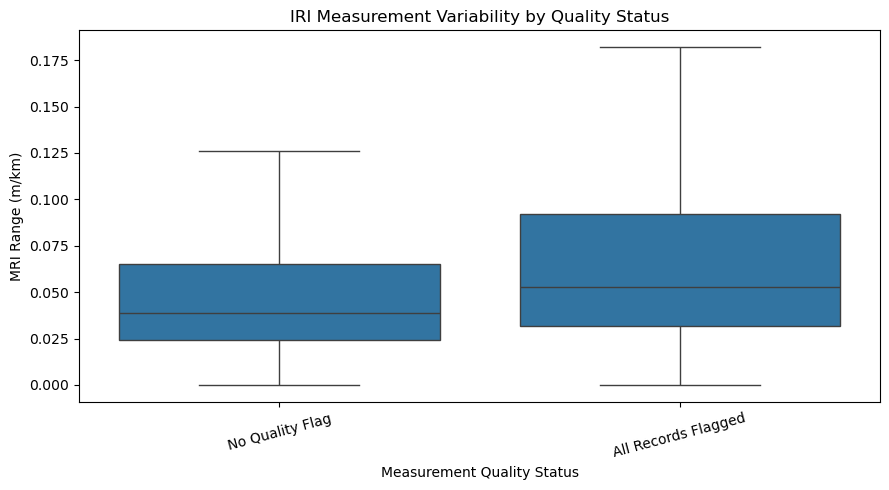

In [38]:
# 3.5 ASSESS IRI QUALITY FLAGS AND MEASUREMENT VARIABILITY

# Create a separate copy of the visit-level summary
iri_quality = iri_visit_summary.copy()

# Classify visits according to their measurement flags
iri_quality["Quality_Status"] = np.select(
    [
        iri_quality["Flagged_Records"] == 0,
        iri_quality["Flagged_Records"] == iri_quality["Number_of_Records"]
    ],
    [
        "No Quality Flag",
        "All Records Flagged"
    ],
    default="Some Records Flagged"
)

# Summarise variability by quality status
quality_summary = iri_quality.groupby(
    "Quality_Status"
).agg(
    Number_of_Visits=("VISIT_NO", "size"),
    Mean_MRI_Range=("MRI_Range", "mean"),
    Median_MRI_Range=("MRI_Range", "median"),
    Maximum_MRI_Range=("MRI_Range", "max"),
    Mean_Standard_Deviation=("Standard_Deviation", "mean")
).reset_index()

print("IRI QUALITY AND VARIABILITY SUMMARY")
display(quality_summary)

# Identify visits with large variability but no quality flags
unflagged_visits = iri_quality[
    iri_quality["Quality_Status"] == "No Quality Flag"
].copy()

unflagged_high_variation = unflagged_visits.sort_values(
    "MRI_Range",
    ascending=False
).head(15)

print("\nVISITS WITH HIGH VARIABILITY BUT NO QUALITY FLAGS")

display(
    unflagged_high_variation[
        [
            "STATE_CODE",
            "SHRP_ID",
            "CONSTRUCTION_NO",
            "VISIT_DATE",
            "VISIT_NO",
            "Number_of_Records",
            "Mean_MRI",
            "Median_MRI",
            "MRI_Range",
            "Standard_Deviation"
        ]
    ]
)

# Visualise variation across quality groups
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=iri_quality,
    x="Quality_Status",
    y="MRI_Range",
    showfliers=False
)

plt.title("IRI Measurement Variability by Quality Status")
plt.xlabel("Measurement Quality Status")
plt.ylabel("MRI Range (m/km)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [39]:
# 3.6 VALIDATE MRI MEASUREMENTS

# Create a separate working copy
iri_validation = iri_df.copy()

# Calculate MRI from the two wheel paths
iri_validation["Calculated_MRI"] = (
    iri_validation["IRI_LEFT_WHEEL_PATH"] +
    iri_validation["IRI_RIGHT_WHEEL_PATH"]
) / 2

# Calculate the absolute difference
iri_validation["MRI_Difference"] = (
    iri_validation["MRI"] -
    iri_validation["Calculated_MRI"]
).abs()

# Check measurement consistency
print("MRI CALCULATION VALIDATION")

print("Total records:", len(iri_validation))

print(
    "Records with complete measurements:",
    iri_validation["MRI_Difference"].notna().sum()
)

print(
    "Records exceeding 0.001 m/km difference:",
    (iri_validation["MRI_Difference"] > 0.001).sum()
)

print(
    "Maximum difference:",
    iri_validation["MRI_Difference"].max()
)

# Display the largest differences
display(
    iri_validation.sort_values(
        "MRI_Difference",
        ascending=False
    )[
        [
            "STATE_CODE",
            "SHRP_ID",
            "CONSTRUCTION_NO",
            "VISIT_DATE",
            "VISIT_NO",
            "RUN_NUMBER",
            "IRI_LEFT_WHEEL_PATH",
            "IRI_RIGHT_WHEEL_PATH",
            "MRI",
            "Calculated_MRI",
            "MRI_Difference"
        ]
    ].head(10)
)


MRI CALCULATION VALIDATION
Total records: 154765
Records with complete measurements: 154763
Records exceeding 0.001 m/km difference: 46
Maximum difference: 0.0010001659393310547


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,RUN_NUMBER,IRI_LEFT_WHEEL_PATH,IRI_RIGHT_WHEEL_PATH,MRI,Calculated_MRI,MRI_Difference
67947,27,1028,1,1993-11-20,27102805,3,1.783,2.709,2.245,2.246,0.001
44690,18,0661,2,1994-02-01,18066104,2,1.170,1.106,1.139,1.138,0.001
116866,48,1060,1,1993-12-15,48106004,3,1.348,1.376,1.361,1.362,0.001
18024,6,0501,2,1995-04-04,06050105,3,1.157,1.333,1.246,1.245,0.001
113991,46,A423,3,1993-10-23,46A42302,3,1.581,1.637,1.610,1.609,0.001
88205,34,1030,1,1989-11-27,34103001,2,3.484,3.770,3.628,3.627,0.001
44108,18,0603,1,1990-04-04,18060301,4,1.809,1.773,1.792,1.791,0.001
57332,21,B350,2,1993-02-05,21B35004,3,1.498,1.134,1.317,1.316,0.001
43347,17,9267,1,1994-03-10,17926704,2,1.136,1.126,1.130,1.131,0.001
122856,48,E430,1,1994-07-12,48E43004,2,2.783,2.939,2.862,2.861,0.001


In [40]:
# 3.7 IDENTIFY VISITS REQUIRING QUALITY REVIEW

# Creatin a separate working copy
iri_review = iri_visit_summary.copy()

# Use visits containing multiple measurements
multiple_runs = iri_review["Number_of_Records"] > 1

# Calculate the 99th percentile of within-visit MRI ranges
variation_limit = iri_review.loc[
    multiple_runs, "MRI_Range"
].quantile(0.99)

# Identify unusually high measurement variation
iri_review["High_Variation"] = (
    multiple_runs &
    (iri_review["MRI_Range"] >= variation_limit)
)

# Identify visits with an LTPP quality flag
iri_review["Quality_Flag"] = (
    iri_review["Flagged_Records"] > 0
)

# Identify visits requiring further investigation
iri_review["Review_Required"] = (
    iri_review["High_Variation"] |
    iri_review["Quality_Flag"]
)

print("IRI QUALITY REVIEW SUMMARY")

print("99th percentile MRI range:", variation_limit)

print(
    "Visits with high variation:",
    iri_review["High_Variation"].sum()
)

print(
    "Visits with quality flags:",
    iri_review["Quality_Flag"].sum()
)

print(
    "Total visits requiring review:",
    iri_review["Review_Required"].sum()
)

# Display visits with the largest variation
display(
    iri_review[
        iri_review["Review_Required"]
    ].sort_values(
        "MRI_Range",
        ascending=False
    ).head(15)
)


IRI QUALITY REVIEW SUMMARY
99th percentile MRI range: 0.3259999752044678
Visits with high variation: 317
Visits with quality flags: 2190
Total visits requiring review: 2463


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,VISIT_NO,Number_of_Records,Unique_Runs,Mean_MRI,Median_MRI,Minimum_MRI,Maximum_MRI,Standard_Deviation,Maximum_Wheelpath_Difference,Flagged_Records,MRI_Range,High_Variation,Quality_Flag,Review_Required
2961,5,0217,4,2013-06-21,050217SN,5,5,4.0050,3.515,2.251,5.665,1.366466,8.225,0,3.414,True,False,True
914,4,0213,4,2019-05-15,040213MD,5,5,3.6910,3.871,2.652,4.404,0.667908,5.263,0,1.752,True,False,True
2957,5,0217,4,2012-01-19,05021710,5,5,3.7450,3.883,2.782,4.330,0.586353,5.548,0,1.548,True,False,True
911,4,0213,3,2016-12-20,040213SU,5,5,2.7170,2.646,1.930,3.373,0.624749,3.296,0,1.443,True,False,True
915,4,0213,4,2019-05-15,040213MF,5,5,3.1880,3.250,2.466,3.816,0.617905,4.765,0,1.350,True,False,True
13960,27,3009,4,2018-09-26,273009GL,5,5,2.7718,2.536,2.424,3.710,0.531412,0.304,0,1.286,True,False,True
2958,5,0217,4,2013-05-03,050217SK,5,5,3.3986,3.350,2.783,3.949,0.451178,4.859,0,1.166,True,False,True
24379,48,5274,3,2003-03-21,48527406,5,5,1.5822,1.149,1.108,2.269,0.613571,0.094,0,1.161,True,False,True
14403,28,1001,3,2004-10-14,28100108,5,5,2.3582,2.223,1.904,3.020,0.419470,1.569,0,1.116,True,False,True
3830,6,0509,3,2005-03-12,06050914,5,5,3.5420,3.753,2.849,3.908,0.423089,0.163,0,1.059,True,False,True


In [41]:
# 4.1 PAVEMENT CONSTRUCTION HISTORY

# Create a copy of the construction dataset
construction_check = construction_df.copy()

# Identify individual pavement sections
section_id = ["STATE_CODE", "SHRP_ID"]

# Summarise construction records for each section
construction_history = construction_check.groupby(
    section_id
).agg(
    Number_of_Records=("CONSTRUCTION_NO", "size"),
    Construction_Numbers=("CONSTRUCTION_NO", "nunique"),
    First_Assignment=("CN_ASSIGN_DATE", "min"),
    Last_Assignment=("CN_ASSIGN_DATE", "max")
).reset_index()

# Display construction history summary
print("CONSTRUCTION HISTORY SUMMARY")

print("Total construction records:", len(construction_check))
print("Unique pavement sections:", len(construction_history))

print(
    "Sections with multiple construction numbers:",
    (construction_history["Construction_Numbers"] > 1).sum()
)

# Examine reasons for construction number changes
print("\nREASONS FOR CONSTRUCTION NUMBER CHANGES")

display(
    construction_check["CN_CHANGE_REASON_EXP"]
    .value_counts(dropna=False)
)

# Display sections with multiple construction numbers
print("\nPAVEMENT SECTIONS WITH MULTIPLE CONSTRUCTION NUMBERS")

display(
    construction_history[
        construction_history["Construction_Numbers"] > 1
    ].sort_values(
        "Construction_Numbers",
        ascending=False
    ).head(15)
)


CONSTRUCTION HISTORY SUMMARY
Total construction records: 7934
Unique pavement sections: 2829
Sections with multiple construction numbers: 2161

REASONS FOR CONSTRUCTION NUMBER CHANGES


CN_CHANGE_REASON_EXP
NaN                                                                                                                                                                                                                            2840
Crack Sealing                                                                                                                                                                                                                   726
Patch Pot Holes - Hand Spread, Compacted with Truck                                                                                                                                                                             394
Asphalt Concrete Overlay                                                                                                                                                                                                        297
Aggregate Seal Coat                                                


PAVEMENT SECTIONS WITH MULTIPLE CONSTRUCTION NUMBERS


,STATE_CODE,SHRP_ID,Number_of_Records,Construction_Numbers,First_Assignment,Last_Assignment
874,19,0605,15,15,1987-01-01,2017-06-01
2710,83,6454,15,15,1987-01-01,2012-08-07
2024,46,0601,14,14,1992-01-01,2019-06-01
871,19,0602,14,14,1987-01-01,2017-06-01
870,19,0601,13,13,1987-01-01,2017-06-01
2025,46,0602,13,13,1992-01-01,2013-06-01
1964,42,0605,12,12,1987-01-01,2004-06-01
2028,46,0605,12,12,1992-01-01,2013-06-01
741,17,0606,11,11,1987-01-01,2008-06-01
1968,42,0659,11,11,1987-01-01,2004-06-01


In [42]:
# 4.2 CONSTRUCTION RECORD MATCHING

# Identifiers for pavement construction periods
id_columns = [
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO"
]

# Get unique construction identifiers
construction_ids = construction_df[
    id_columns
].drop_duplicates()

# Match IRI records to construction history
iri_match = iri_df[id_columns].merge(
    construction_ids,
    on=id_columns,
    how="left",
    indicator=True
)

# Match rutting records to construction history
rutting_match = rutting_df[id_columns].merge(
    construction_ids,
    on=id_columns,
    how="left",
    indicator=True
)

print("IRI CONSTRUCTION RECORD MATCHING")
display(iri_match["_merge"].value_counts())

print("\nRUTTING CONSTRUCTION RECORD MATCHING")
display(rutting_match["_merge"].value_counts())


IRI CONSTRUCTION RECORD MATCHING


_merge
both          154765
left_only          0
right_only         0
Name: count, dtype: int64


RUTTING CONSTRUCTION RECORD MATCHING


_merge
both          21527
left_only         0
right_only        0
Name: count, dtype: int64

In [43]:
# 4.3 INVESTIGATE CONSTRUCTION NUMBER CHANGES

# Display the most common reasons for construction changes
print("MOST COMMON CONSTRUCTION CHANGE REASONS")

display(
    construction_df["CN_CHANGE_REASON_EXP"]
    .value_counts(dropna=False)
    .head(20)
)

# Select three sections with the most construction numbers
selected_sections = construction_history.nlargest(
    3, "Construction_Numbers"
)[["STATE_CODE", "SHRP_ID"]]

# Retrieve their construction histories
selected_history = construction_df.merge(
    selected_sections,
    on=["STATE_CODE", "SHRP_ID"],
    how="inner"
)

# Display construction changes in chronological order
print("\nDETAILED CONSTRUCTION HISTORY")

display(
    selected_history[
        [
            "STATE_CODE",
            "SHRP_ID",
            "CONSTRUCTION_NO",
            "CN_ASSIGN_DATE",
            "CN_CHANGE_REASON_EXP",
            "PAVEMENT_FAMILY_EXP"
        ]
    ].sort_values(
        ["STATE_CODE", "SHRP_ID", "CN_ASSIGN_DATE"]
    )
)


MOST COMMON CONSTRUCTION CHANGE REASONS


CN_CHANGE_REASON_EXP
NaN                                                                                                          2840
Crack Sealing                                                                                                 726
Patch Pot Holes - Hand Spread, Compacted with Truck                                                           394
Asphalt Concrete Overlay                                                                                      297
Aggregate Seal Coat                                                                                           282
Partial depth patching of PCC pavements at joints                                                             243
Skin Patching (hand tools/hot pot to apply liquid asphalt and aggregate)                                      211
Transverse Joint Sealing, Lane-Shoulder Longitudinal Joint Sealing                                            194
Mill Off AC and Overlay with AC                                    


DETAILED CONSTRUCTION HISTORY


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,CN_ASSIGN_DATE,CN_CHANGE_REASON_EXP,PAVEMENT_FAMILY_EXP
0,19,0602,1,1987-01-01,NaN,Jointed reinforced concrete pavement
1,19,0602,2,1990-01-11,Partial Depth Patching of PCC Pavement Other T...,Jointed reinforced concrete pavement
2,19,0602,3,1990-04-30,Partial Depth Patching of PCC Pavement Other T...,Jointed reinforced concrete pavement
3,19,0602,4,1990-08-03,Partial Depth Patching of PCC Pavement Other T...,Jointed reinforced concrete pavement
4,19,0602,5,1990-10-10,"Crack Sealing, Grinding Surface",Jointed reinforced concrete pavement
5,19,0602,6,1992-01-30,Crack Sealing,Jointed reinforced concrete pavement
6,19,0602,7,1993-08-11,Partial Depth Patching of PCC Pavement Other T...,Jointed reinforced concrete pavement
7,19,0602,8,1997-04-25,"Full Depth Transverse Joint Repair Patch, Full...",Jointed reinforced concrete pavement
8,19,0602,9,1997-07-01,"AC Shoulder Restoration, Asphalt Concrete Over...",Asphalt concrete over Portland cement concrete
9,19,0602,10,2003-06-01,Crack Sealing,Asphalt concrete over Portland cement concrete


In [44]:

# 4.4 MEASUREMENT DATES AGAINST CONSTRUCTION HISTORY

# Define pavement identifiers
id_columns = [
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO"
]

# Summarise construction assignment dates
construction_dates = construction_df.groupby(
    id_columns, as_index=False
).agg(
    Assignment_Date=("CN_ASSIGN_DATE", "min"),
    Assignment_Records=("CN_ASSIGN_DATE", "size"),
    Different_Dates=("CN_ASSIGN_DATE", "nunique")
)

# Identify the next construction-number assignment
construction_dates = construction_dates.sort_values(
    ["STATE_CODE", "SHRP_ID", "Assignment_Date", "CONSTRUCTION_NO"]
)

construction_dates["Next_Assignment_Date"] = (
    construction_dates.groupby(
        ["STATE_CODE", "SHRP_ID"]
    )["Assignment_Date"].shift(-1)
)

print("CONSTRUCTION IDENTIFIER CHECK")

print(
    "Identifiers with multiple construction records:",
    (construction_dates["Assignment_Records"] > 1).sum()
)

print(
    "Identifiers with conflicting assignment dates:",
    (construction_dates["Different_Dates"] > 1).sum()
)

# Check IRI and rutting dates
for name, data, date_column in [
    ("IRI", iri_df, "VISIT_DATE"),
    ("RUTTING", rutting_df, "SURVEY_DATE")
]:

    date_check = data[
        id_columns + [date_column]
    ].merge(
        construction_dates,
        on=id_columns,
        how="left",
        validate="many_to_one"
    )

    # Measurements before the assigned construction period
    before_assignment = (
        date_check[date_column] <
        date_check["Assignment_Date"]
    )

    # Measurements on or after the next assignment
    after_next_assignment = (
        date_check[date_column] >=
        date_check["Next_Assignment_Date"]
    )

    print("\n", name, "DATE VALIDATION")
    print("Total measurements:", len(date_check))
    print("Before assignment:", before_assignment.sum())
    print("On or after next assignment:",
          after_next_assignment.sum())

    print("\nRecords requiring date investigation:")

    display(
        date_check[
            before_assignment | after_next_assignment
        ].head(10)
    )


CONSTRUCTION IDENTIFIER CHECK
Identifiers with multiple construction records: 0
Identifiers with conflicting assignment dates: 0

 IRI DATE VALIDATION
Total measurements: 154765
Before assignment: 0
On or after next assignment: 0

Records requiring date investigation:


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,Assignment_Date,Assignment_Records,Different_Dates,Next_Assignment_Date



 RUTTING DATE VALIDATION
Total measurements: 21527
Before assignment: 0
On or after next assignment: 0

Records requiring date investigation:


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,SURVEY_DATE,Assignment_Date,Assignment_Records,Different_Dates,Next_Assignment_Date


In [46]:
# 4.5 ASSESS PAVEMENT MONITORING HISTORIES

# Pavement identifiers
id_columns = [
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO"
]

# Summarise IRI monitoring records
iri_monitoring = iri_df.groupby(
    id_columns
).agg(
    IRI_Records=("MRI", "size"),
    IRI_Visits=("VISIT_NO", "nunique"),
    IRI_Survey_Dates=("VISIT_DATE", "nunique"),
    First_IRI_Date=("VISIT_DATE", "min"),
    Last_IRI_Date=("VISIT_DATE", "max")
).reset_index()

# Calculate IRI observation period in years
iri_monitoring["IRI_Years"] = (
    iri_monitoring["Last_IRI_Date"] -
    iri_monitoring["First_IRI_Date"]
).dt.days / 365.25

# Summarise rutting monitoring records
rutting_monitoring = rutting_df.groupby(
    id_columns
).agg(
    Rutting_Records=("MAX_MEAN_DEPTH_1_8", "size"),
    Rutting_Survey_Dates=("SURVEY_DATE", "nunique"),
    First_Rutting_Date=("SURVEY_DATE", "min"),
    Last_Rutting_Date=("SURVEY_DATE", "max")
).reset_index()

# Calculate rutting observation period in years
rutting_monitoring["Rutting_Years"] = (
    rutting_monitoring["Last_Rutting_Date"] -
    rutting_monitoring["First_Rutting_Date"]
).dt.days / 365.25

# Combine monitoring summaries with construction history
monitoring_summary = construction_df[
    id_columns + [
        "CN_ASSIGN_DATE",
        "CN_CHANGE_REASON_EXP"
    ]
].merge(
    iri_monitoring,
    on=id_columns,
    how="left"
).merge(
    rutting_monitoring,
    on=id_columns,
    how="left"
)

# Display monitoring availability
print("PAVEMENT MONITORING SUMMARY")

print("Construction periods:", len(monitoring_summary))

print(
    "Periods with IRI measurements:",
    monitoring_summary["IRI_Records"].notna().sum()
)

print(
    "Periods with rutting measurements:",
    monitoring_summary["Rutting_Records"].notna().sum()
)

print(
    "Periods with at least two IRI survey dates:",
    (monitoring_summary["IRI_Survey_Dates"] >= 2).sum()
)

print(
    "Periods with at least two rutting survey dates:",
    (monitoring_summary["Rutting_Survey_Dates"] >= 2).sum()
)

print(
    "Periods with at least two survey dates for both:",
    (
        (monitoring_summary["IRI_Survey_Dates"] >= 2) &
        (monitoring_summary["Rutting_Survey_Dates"] >= 2)
    ).sum()
)

# Examine monitoring duration
print("\nIRI MONITORING DURATION (YEARS)")
display(monitoring_summary["IRI_Years"].describe())

print("\nRUTTING MONITORING DURATION (YEARS)")
display(monitoring_summary["Rutting_Years"].describe())

# Display sample monitoring histories
print("\nSAMPLE PAVEMENT MONITORING HISTORIES")

display(
    monitoring_summary[
        id_columns + [
            "IRI_Visits",
            "IRI_Survey_Dates",
            "IRI_Years",
            "Rutting_Survey_Dates",
            "Rutting_Years"
        ]
    ].head(15)
)


PAVEMENT MONITORING SUMMARY
Construction periods: 7934
Periods with IRI measurements: 6813
Periods with rutting measurements: 5917
Periods with at least two IRI survey dates: 4774
Periods with at least two rutting survey dates: 3920
Periods with at least two survey dates for both: 3628

IRI MONITORING DURATION (YEARS)


count    6813.000000
mean        4.446198
std         5.460497
min         0.000000
25%         0.000000
50%         2.737851
75%         6.943190
max        33.812457
Name: IRI_Years, dtype: float64


RUTTING MONITORING DURATION (YEARS)


count    5917.000000
mean        4.027999
std         5.174526
min         0.000000
25%         0.000000
50%         2.121834
75%         6.310746
max        34.724162
Name: Rutting_Years, dtype: float64


SAMPLE PAVEMENT MONITORING HISTORIES


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,IRI_Visits,IRI_Survey_Dates,IRI_Years,Rutting_Survey_Dates,Rutting_Years
0,1,0100,1,NaN,NaN,NaN,NaN,NaN
1,1,0101,1,17.0,17.0,9.511294,15.0,11.058179
2,1,0102,1,16.0,16.0,8.429843,12.0,9.004791
3,1,0102,2,2.0,2.0,1.018480,3.0,1.273101
4,1,0103,1,9.0,9.0,9.314168,12.0,11.058179
5,1,0104,1,10.0,10.0,9.314168,12.0,11.058179
6,1,0105,1,9.0,9.0,9.314168,12.0,11.058179
7,1,0106,1,10.0,10.0,10.691307,12.0,11.058179
8,1,0107,1,5.0,5.0,5.095140,4.0,6.110883
9,1,0107,2,1.0,1.0,0.000000,1.0,0.000000


In [47]:
# 4.6 EXAMINE IRI AND RUTTING MONITORING OVERLAP

# Select construction periods with repeated IRI and rutting surveys
paired_monitoring = monitoring_summary[
    (monitoring_summary["IRI_Survey_Dates"] >= 2) &
    (monitoring_summary["Rutting_Survey_Dates"] >= 2)
].copy()

# Calculate the overlapping monitoring period
paired_monitoring["Overlap_Start"] = paired_monitoring[
    ["First_IRI_Date", "First_Rutting_Date"]
].max(axis=1)

paired_monitoring["Overlap_End"] = paired_monitoring[
    ["Last_IRI_Date", "Last_Rutting_Date"]
].min(axis=1)

paired_monitoring["Overlap_Days"] = (
    paired_monitoring["Overlap_End"] -
    paired_monitoring["Overlap_Start"]
).dt.days

print("IRI AND RUTTING MONITORING OVERLAP")

print("Periods with repeated measurements:", len(paired_monitoring))

print(
    "Periods with overlapping monitoring windows:",
    (paired_monitoring["Overlap_Days"] > 0).sum()
)

print(
    "Periods where windows meet on one date:",
    (paired_monitoring["Overlap_Days"] == 0).sum()
)

print(
    "Periods without overlapping monitoring windows:",
    (paired_monitoring["Overlap_Days"] < 0).sum()
)

# Identifying survey dates shared by both indicators
iri_dates = iri_df[
    id_columns + ["VISIT_DATE"]
].drop_duplicates().rename(
    columns={"VISIT_DATE": "Survey_Date"}
)

rutting_dates = rutting_df[
    id_columns + ["SURVEY_DATE"]
].drop_duplicates().rename(
    columns={"SURVEY_DATE": "Survey_Date"}
)

shared_dates = iri_dates.merge(
    rutting_dates,
    on=id_columns + ["Survey_Date"],
    how="inner"
)

shared_counts = shared_dates.groupby(
    id_columns
).size().reset_index(name="Shared_Survey_Dates")

# Add the count of shared dates
paired_monitoring = paired_monitoring.merge(
    shared_counts,
    on=id_columns,
    how="left"
)

paired_monitoring["Shared_Survey_Dates"] = (
    paired_monitoring["Shared_Survey_Dates"]
    .fillna(0)
    .astype(int)
)

print("\nMATCHING SURVEY DATES")

print(
    "Periods with at least one shared survey date:",
    (paired_monitoring["Shared_Survey_Dates"] >= 1).sum()
)

print(
    "Periods with at least two shared survey dates:",
    (paired_monitoring["Shared_Survey_Dates"] >= 2).sum()
)

# monitoring summary
display(
    paired_monitoring[
        id_columns + [
            "IRI_Survey_Dates",
            "Rutting_Survey_Dates",
            "IRI_Years",
            "Rutting_Years",
            "Overlap_Days",
            "Shared_Survey_Dates"
        ]
    ].head(15)
)


IRI AND RUTTING MONITORING OVERLAP
Periods with repeated measurements: 3628
Periods with overlapping monitoring windows: 3602
Periods where windows meet on one date: 1
Periods without overlapping monitoring windows: 25

MATCHING SURVEY DATES
Periods with at least one shared survey date: 757
Periods with at least two shared survey dates: 313


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,IRI_Survey_Dates,Rutting_Survey_Dates,IRI_Years,Rutting_Years,Overlap_Days,Shared_Survey_Dates
0,1,0101,1,17.0,15.0,9.511294,11.058179,3468,1
1,1,0102,1,16.0,12.0,8.429843,9.004791,3079,1
2,1,0102,2,2.0,3.0,1.018480,1.273101,367,0
3,1,0103,1,9.0,12.0,9.314168,11.058179,3396,1
4,1,0104,1,10.0,12.0,9.314168,11.058179,3396,1
5,1,0105,1,9.0,12.0,9.314168,11.058179,3396,1
6,1,0106,1,10.0,12.0,10.691307,11.058179,3899,1
7,1,0107,1,5.0,4.0,5.095140,6.110883,1861,1
8,1,0108,1,11.0,12.0,10.694045,11.055441,3899,1
9,1,0109,1,9.0,12.0,9.314168,11.055441,3395,1


In [48]:
# 4.7 EXAMINE FIRST MEASUREMENT DATES

# Create a separate working copy
baseline_check = monitoring_summary.copy()

# Cal delay between construction assignment and first IRI survey
baseline_check["IRI_Start_Delay"] = (
    baseline_check["First_IRI_Date"] -
    baseline_check["CN_ASSIGN_DATE"]
).dt.days / 365.25

# Calculate delay between construction assignment and first rutting survey
baseline_check["Rutting_Start_Delay"] = (
    baseline_check["First_Rutting_Date"] -
    baseline_check["CN_ASSIGN_DATE"]
).dt.days / 365.25

print("IRI FIRST MEASUREMENT DELAY (YEARS)")
display(baseline_check["IRI_Start_Delay"].describe())

print("\nRUTTING FIRST MEASUREMENT DELAY (YEARS)")
display(baseline_check["Rutting_Start_Delay"].describe())

# Identify long gaps before the first observed measurement
print("\nCONSTRUCTION PERIODS WITH LONGEST IRI START DELAYS")

display(
    baseline_check[
        id_columns + [
            "CN_ASSIGN_DATE",
            "First_IRI_Date",
            "IRI_Start_Delay",
            "IRI_Survey_Dates"
        ]
    ].sort_values(
        "IRI_Start_Delay",
        ascending=False
    ).head(10)
)

print("\nCONSTRUCTION PERIODS WITH LONGEST RUTTING START DELAYS")

display(
    baseline_check[
        id_columns + [
            "CN_ASSIGN_DATE",
            "First_Rutting_Date",
            "Rutting_Start_Delay",
            "Rutting_Survey_Dates"
        ]
    ].sort_values(
        "Rutting_Start_Delay",
        ascending=False
    ).head(10)
)


IRI FIRST MEASUREMENT DELAY (YEARS)


count    6813.000000
mean        1.338703
std         1.369804
min         0.000000
25%         0.339493
50%         0.898015
75%         1.883641
max        10.422998
Name: IRI_Start_Delay, dtype: float64


RUTTING FIRST MEASUREMENT DELAY (YEARS)


count    5917.000000
mean        1.613393
std         1.715156
min         0.000000
25%         0.421629
50%         1.010267
75%         2.368241
max        12.859685
Name: Rutting_Start_Delay, dtype: float64


CONSTRUCTION PERIODS WITH LONGEST IRI START DELAYS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,CN_ASSIGN_DATE,First_IRI_Date,IRI_Start_Delay,IRI_Survey_Dates
5213,40,0505,1,1987-01-01,1997-06-04,10.422998,1.0
5229,40,0509,1,1987-01-01,1997-06-04,10.422998,1.0
5217,40,0506,1,1987-01-01,1997-06-04,10.422998,1.0
5205,40,0503,1,1987-01-01,1997-06-04,10.422998,1.0
5201,40,0502,1,1987-01-01,1997-06-04,10.422998,1.0
5198,40,0501,1,1987-01-01,1997-06-04,10.422998,1.0
5221,40,0507,1,1987-01-01,1997-06-04,10.422998,1.0
5225,40,0508,1,1987-01-01,1997-06-04,10.422998,1.0
5209,40,0504,1,1987-01-01,1997-06-04,10.422998,1.0
750,5,A601,1,1987-01-01,1996-09-12,9.697467,1.0



CONSTRUCTION PERIODS WITH LONGEST RUTTING START DELAYS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,CN_ASSIGN_DATE,First_Rutting_Date,Rutting_Start_Delay,Rutting_Survey_Dates
1584,10,0211,1,1992-01-01,2004-11-10,12.859685,1.0
1552,10,0203,1,1992-01-01,2004-11-10,12.859685,1.0
2342,18,A430,2,1991-10-04,2004-06-30,12.739220,1.0
3436,27,3007,1,1993-01-01,2005-07-20,12.547570,1.0
3435,27,3005,1,1993-01-01,2005-07-20,12.547570,1.0
3445,27,3012,1,1993-01-01,2005-07-19,12.544832,1.0
3444,27,3010,1,1993-01-01,2005-07-19,12.544832,1.0
3440,27,3009,1,1993-01-01,2005-07-19,12.544832,1.0
1593,10,0260,1,1992-01-01,2003-11-10,11.857632,1.0
1551,10,0202,1,1992-01-01,2003-10-30,11.827515,2.0


In [49]:
# 4.8 INVESTIGATE CONSTRUCTION ASSIGNMENT DATES

# Examining the most common construction assignment dates
print("MOST COMMON CONSTRUCTION ASSIGNMENT DATES")

display(
    construction_df["CN_ASSIGN_DATE"]
    .value_counts()
    .head(15)
)

# Identify assignments recorded on 1 January
construction_check = construction_df.copy()

construction_check["January_1_Assignment"] = (
    (construction_check["CN_ASSIGN_DATE"].dt.month == 1) &
    (construction_check["CN_ASSIGN_DATE"].dt.day == 1)
)

print("\nCONSTRUCTION ASSIGNMENT DATE CHECK")

print("Total records:", len(construction_check))

print(
    "Records assigned on 1 January:",
    construction_check["January_1_Assignment"].sum()
)

print(
    "Percentage assigned on 1 January:",
    round(
        construction_check["January_1_Assignment"].mean() * 100,
        2
    )
)

# Examine the reasons associated with these assignments
print("\nCHANGE REASONS FOR 1 JANUARY ASSIGNMENTS")

display(
    construction_check.loc[
        construction_check["January_1_Assignment"],
        "CN_CHANGE_REASON_EXP"
    ].value_counts(dropna=False).head(15)
)


MOST COMMON CONSTRUCTION ASSIGNMENT DATES


CN_ASSIGN_DATE
1987-01-01    1138
1993-01-01     174
1988-01-01     136
1992-01-01     130
1994-01-01      89
1988-07-01      74
2003-06-01      73
2008-06-01      68
1998-06-01      66
2011-06-01      60
1991-01-01      57
2012-06-01      55
2013-06-01      54
2004-06-01      54
1995-01-01      54
Name: count, dtype: int64


CONSTRUCTION ASSIGNMENT DATE CHECK
Total records: 7934
Records assigned on 1 January: 2042
Percentage assigned on 1 January: 25.74

CHANGE REASONS FOR 1 JANUARY ASSIGNMENTS


CN_CHANGE_REASON_EXP
NaN                                                                                                                        1960
Patch Pot Holes - Hand Spread, Compacted with Truck                                                                          26
Crack Sealing                                                                                                                22
PCC Slab Replacement                                                                                                          4
Partial depth patching of PCC pavements at joints                                                                             3
Crack Sealing, Patch Pot Holes - Hand Spread, Compacted with Truck                                                            3
Machine Premix Patch (placing premix with paver roller)                                                                       3
Full Depth Transverse Joint Repair Patch, Full Depth Patching of PCC Pavement Other

In [50]:
# 4.9 EXAMINing FIRST RECORDED PAVEMENT CONDITION
# Identifying IRI records from the first survey date
iri_first = iri_df.merge(
    iri_monitoring[
        id_columns + ["First_IRI_Date"]
    ],
    on=id_columns,
    how="inner"
)

iri_first = iri_first[
    iri_first["VISIT_DATE"] ==
    iri_first["First_IRI_Date"]
].copy()

# Summarise first IRI measurements
iri_baseline = iri_first.groupby(
    id_columns
).agg(
    First_IRI_Date=("VISIT_DATE", "first"),
    First_MRI_Min=("MRI", "min"),
    First_MRI_Median=("MRI", "median"),
    First_MRI_Max=("MRI", "max"),
    Number_of_Runs=("MRI", "count"),
    Number_of_Visits=("VISIT_NO", "nunique")
).reset_index()

# Calculate variation on first survey date
iri_baseline["First_MRI_Range"] = (
    iri_baseline["First_MRI_Max"] -
    iri_baseline["First_MRI_Min"]
)

print("FIRST IRI SURVEY SUMMARY")

print("Construction periods:", len(iri_baseline))

display(
    iri_baseline[
        [
            "First_MRI_Min",
            "First_MRI_Median",
            "First_MRI_Max",
            "Number_of_Runs",
            "First_MRI_Range"
        ]
    ].describe()
)

print("\nFIRST SURVEYS WITH LARGEST MRI VARIATION")

display(
    iri_baseline.sort_values(
        "First_MRI_Range",
        ascending=False
    ).head(10)
)

#  rutting measurements from the first survey date
rutting_first = rutting_df.merge(
    rutting_monitoring[
        id_columns + ["First_Rutting_Date"]
    ],
    on=id_columns,
    how="inner"
)

rutting_first = rutting_first[
    rutting_first["SURVEY_DATE"] ==
    rutting_first["First_Rutting_Date"]
].copy()

# Summary of first rutting measurements
rutting_baseline = rutting_first.groupby(
    id_columns
).agg(
    First_Rutting_Date=("SURVEY_DATE", "first"),
    First_Rut_Min=("MAX_MEAN_DEPTH_1_8", "min"),
    First_Rut_Median=("MAX_MEAN_DEPTH_1_8", "median"),
    First_Rut_Max=("MAX_MEAN_DEPTH_1_8", "max"),
    Number_of_Records=("MAX_MEAN_DEPTH_1_8", "count")
).reset_index()

print("\nFIRST RUTTING SURVEY SUMMARY")

print("Construction periods:", len(rutting_baseline))

display(
    rutting_baseline[
        [
            "First_Rut_Min",
            "First_Rut_Median",
            "First_Rut_Max",
            "Number_of_Records"
        ]
    ].describe()
)


FIRST IRI SURVEY SUMMARY
Construction periods: 6813


,First_MRI_Min,First_MRI_Median,First_MRI_Max,Number_of_Runs,First_MRI_Range
count,6813.000000,6813.000000,6813.000000,6813.000000,6813.000000
mean,1.416511,1.446317,1.477013,4.997358,0.060502
std,0.684415,0.697881,0.711735,0.756645,0.069741
min,0.319000,0.333000,0.342000,1.000000,0.000000
25%,0.931000,0.950000,0.967000,5.000000,0.024000
50%,1.253000,1.279000,1.307000,5.000000,0.040000
75%,1.723000,1.757000,1.798000,5.000000,0.070000
max,5.363000,5.591000,5.618000,20.000000,1.286000



FIRST SURVEYS WITH LARGEST MRI VARIATION


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,First_IRI_Date,First_MRI_Min,First_MRI_Median,First_MRI_Max,Number_of_Runs,Number_of_Visits,First_MRI_Range
2972,27,3009,4,2018-09-26,2.424,2.5360,3.710,5,1,1.286
5364,48,5274,3,2003-03-21,1.108,1.1490,2.269,5,1,1.161
3131,28,5803,4,2003-05-02,2.158,2.3380,2.998,5,1,0.840
4144,37,1817,6,2015-03-24,1.086,1.1490,1.819,5,1,0.733
6783,90,A340,6,1997-04-28,3.889,4.2520,4.614,5,1,0.725
287,4,0560,1,1990-02-05,1.566,1.6970,2.254,5,1,0.688
279,4,0509,5,2002-11-04,1.886,1.9760,2.569,5,1,0.683
3522,30,0560,1,1991-05-25,2.645,2.9675,3.324,4,1,0.679
872,6,0663,10,2005-04-24,3.703,3.9690,4.377,5,1,0.674
1197,8,6002,3,2004-10-22,2.875,2.9630,3.526,5,1,0.651



FIRST RUTTING SURVEY SUMMARY
Construction periods: 5917


,First_Rut_Min,First_Rut_Median,First_Rut_Max,Number_of_Records
count,5917.000000,5917.000000,5917.000000,5917.000000
mean,4.999493,4.999662,4.999831,1.001521
std,3.541433,3.541278,3.541147,0.050331
min,0.000000,0.000000,0.000000,1.000000
25%,3.000000,3.000000,3.000000,1.000000
50%,4.000000,4.000000,4.000000,1.000000
75%,6.000000,6.000000,6.000000,1.000000
max,29.000000,29.000000,29.000000,4.000000


In [51]:

# 4.10 CHECK CONSTRUCTION ASSIGNMENT DATE PATTERNS

# Summary assignment dates by construction number
assignment_summary = construction_check.groupby(
    "CONSTRUCTION_NO"
).agg(
    Total_Records=("CN_ASSIGN_DATE", "size"),
    January_1_Records=("January_1_Assignment", "sum"),
    Missing_Change_Reasons=(
        "CN_CHANGE_REASON_EXP",
        lambda x: x.isna().sum()
    )
).reset_index()

# Calculate percentage assigned on 1 January
assignment_summary["January_1_Percentage"] = (
    assignment_summary["January_1_Records"] /
    assignment_summary["Total_Records"] * 100
)

print("CONSTRUCTION ASSIGNMENT DATE PATTERNS")

display(assignment_summary.head(15))


CONSTRUCTION ASSIGNMENT DATE PATTERNS


,CONSTRUCTION_NO,Total_Records,January_1_Records,Missing_Change_Reasons,January_1_Percentage
0,1,2829,1960,2829,69.282432
1,2,2161,25,7,1.156872
2,3,1240,27,2,2.177419
3,4,702,11,1,1.566952
4,5,417,7,0,1.678657
5,6,252,5,1,1.984127
6,7,147,3,0,2.040816
7,8,82,2,0,2.439024
8,9,44,2,0,4.545455
9,10,27,0,0,0.000000


In [52]:
# 4.11 ASSESS FIRST-SURVEY MEASUREMENT RELIABILITY
# Assess the first IRI surveys
iri_first_quality = iri_first.groupby(
    id_columns
).agg(
    Records=("MRI", "size"),
    Missing_MRI=("MRI", lambda x: x.isna().sum()),
    Visits=("VISIT_NO", "nunique"),
    Flagged_Records=("MRI_FLAG", "count"),
    Minimum_MRI=("MRI", "min"),
    Maximum_MRI=("MRI", "max")
).reset_index()

# Calculate variation in MRI
iri_first_quality["MRI_Range"] = (
    iri_first_quality["Maximum_MRI"] -
    iri_first_quality["Minimum_MRI"]
)

print("FIRST IRI SURVEY QUALITY")

print("Periods:", len(iri_first_quality))

print(
    "Periods with multiple visit identifiers:",
    (iri_first_quality["Visits"] > 1).sum()
)

print(
    "Periods with quality flags:",
    (iri_first_quality["Flagged_Records"] > 0).sum()
)

print(
    "Periods with missing MRI:",
    (iri_first_quality["Missing_MRI"] > 0).sum()
)

print(
    "Periods exceeding the variability screening value:",
    (iri_first_quality["MRI_Range"] >= variation_limit).sum()
)

# Assess the first rutting surveys
rutting_first_quality = rutting_first.groupby(
    id_columns
).agg(
    Records=("MAX_MEAN_DEPTH_1_8", "size"),
    Missing_Rut=(
        "MAX_MEAN_DEPTH_1_8",
        lambda x: x.isna().sum()
    ),
    Visits=("VISIT_NO", "nunique"),
    Devices=("T_PROF_DEVICE_CODE", "nunique"),
    Flagged_Records=("MAX_MEAN_DEPTH_1_8_FLAG", "count")
).reset_index()

print("\nFIRST RUTTING SURVEY QUALITY")

print("Periods:", len(rutting_first_quality))

print(
    "Periods with multiple records:",
    (rutting_first_quality["Records"] > 1).sum()
)

print(
    "Periods with multiple devices:",
    (rutting_first_quality["Devices"] > 1).sum()
)

print(
    "Periods with quality flags:",
    (rutting_first_quality["Flagged_Records"] > 0).sum()
)

print(
    "Periods with missing rut depth:",
    (rutting_first_quality["Missing_Rut"] > 0).sum()
)


FIRST IRI SURVEY QUALITY
Periods: 6813
Periods with multiple visit identifiers: 87
Periods with quality flags: 3
Periods with missing MRI: 0
Periods exceeding the variability screening value: 85

FIRST RUTTING SURVEY QUALITY
Periods: 5917
Periods with multiple records: 7
Periods with multiple devices: 4
Periods with quality flags: 0
Periods with missing rut depth: 0


In [53]:
# 5.1 FINAL DATA CLEANING

# Create copies of the original datasets
iri_clean = iri_df.copy()
rutting_clean = rutting_df.copy()

# Record the original number of observations
original_iri = len(iri_clean)
original_rutting = len(rutting_clean)

# Identify exact duplicate records for the audit
iri_duplicates = iri_clean[
    iri_clean.duplicated()
].copy()

rutting_duplicates = rutting_clean[
    rutting_clean.duplicated()
].copy()

# Remove exact duplicate records
iri_clean = iri_clean.drop_duplicates().copy()
rutting_clean = rutting_clean.drop_duplicates().copy()

# Convert measurement dates to datetime
iri_clean["VISIT_DATE"] = pd.to_datetime(
    iri_clean["VISIT_DATE"], errors="coerce"
)

rutting_clean["SURVEY_DATE"] = pd.to_datetime(
    rutting_clean["SURVEY_DATE"], errors="coerce"
)

# Ensure the main measurements are numeric
iri_clean["MRI"] = pd.to_numeric(
    iri_clean["MRI"], errors="coerce"
)

rutting_clean["MAX_MEAN_DEPTH_1_8"] = pd.to_numeric(
    rutting_clean["MAX_MEAN_DEPTH_1_8"], errors="coerce"
)

# Identify incomplete records
iri_incomplete = iri_clean[
    iri_clean[
        id_columns + ["VISIT_DATE", "MRI"]
    ].isna().any(axis=1)
].copy()

rutting_incomplete = rutting_clean[
    rutting_clean[
        id_columns + ["SURVEY_DATE", "MAX_MEAN_DEPTH_1_8"]
    ].isna().any(axis=1)
].copy()

# Exclude incomplete records from the working datasets
iri_clean = iri_clean.drop(
    index=iri_incomplete.index
).copy()

rutting_clean = rutting_clean.drop(
    index=rutting_incomplete.index
).copy()

# Preserve measurement quality indicators
iri_clean["Quality_Flagged"] = (
    iri_clean["MRI_FLAG"].notna()
)

rutting_clean["Quality_Flagged"] = (
    rutting_clean["MAX_MEAN_DEPTH_1_8_FLAG"].notna()
)

# Sort the observations chronologically
iri_clean = iri_clean.sort_values(
    id_columns + ["VISIT_DATE", "VISIT_NO", "RUN_NUMBER"]
).reset_index(drop=True)

rutting_clean = rutting_clean.sort_values(
    id_columns + ["SURVEY_DATE", "VISIT_NO", "RUN_NUMBER"]
).reset_index(drop=True)

# Display cleaning summary
print("DATA CLEANING SUMMARY")

print("\nIRI DATASET")
print("Original records:", original_iri)
print("Exact duplicates:", len(iri_duplicates))
print("Incomplete records:", len(iri_incomplete))
print("Remaining records:", len(iri_clean))
print("Flagged records retained:", iri_clean["Quality_Flagged"].sum())

print("\nRUTTING DATASET")
print("Original records:", original_rutting)
print("Exact duplicates:", len(rutting_duplicates))
print("Incomplete records:", len(rutting_incomplete))
print("Remaining records:", len(rutting_clean))
print("Flagged records retained:", rutting_clean["Quality_Flagged"].sum())


DATA CLEANING SUMMARY

IRI DATASET
Original records: 154765
Exact duplicates: 14
Incomplete records: 2
Remaining records: 154749
Flagged records retained: 10685

RUTTING DATASET
Original records: 21527
Exact duplicates: 0
Incomplete records: 0
Remaining records: 21527
Flagged records retained: 60


In [54]:
# 5.2A PREPARE IRI SURVEY MEASUREMENTS

# Summarise the MRI measurements within each visit
iri_visit_data = iri_clean.groupby(
    id_columns + ["VISIT_DATE", "VISIT_NO"],
    dropna=False
).agg(
    MRI=("MRI", "median"),
    Number_of_Runs=("MRI", "size"),
    Minimum_MRI=("MRI", "min"),
    Maximum_MRI=("MRI", "max"),
    Quality_Flagged=("Quality_Flagged", "max")
).reset_index()

# Calculate measurement variation within each visit
iri_visit_data["MRI_Range"] = (
    iri_visit_data["Maximum_MRI"] -
    iri_visit_data["Minimum_MRI"]
)

# Prepare one provisional observation per survey date
iri_surveys = iri_visit_data.groupby(
    id_columns + ["VISIT_DATE"],
    dropna=False
).agg(
    MRI=("MRI", "median"),
    Number_of_Visits=("VISIT_NO", "size"),
    Flagged_Visits=("Quality_Flagged", "sum"),
    Maximum_MRI_Range=("MRI_Range", "max"),
    Minimum_Visit_MRI=("MRI", "min"),
    Maximum_Visit_MRI=("MRI", "max")
).reset_index()

# Calculate differences between visits on the same date
iri_surveys["Across_Visit_Range"] = (
    iri_surveys["Maximum_Visit_MRI"] -
    iri_surveys["Minimum_Visit_MRI"]
)

# Identify observations requiring quality review
iri_surveys["Review_Required"] = (
    (iri_surveys["Flagged_Visits"] > 0) |
    (iri_surveys["Number_of_Visits"] > 1) |
    (iri_surveys["Maximum_MRI_Range"] >= variation_limit)
)

# Arrange observations chronologically
iri_surveys = iri_surveys.sort_values(
    id_columns + ["VISIT_DATE"]
).reset_index(drop=True)

print("IRI SURVEY DATASET")
print("Original cleaned records:", len(iri_clean))
print("Individual visits:", len(iri_visit_data))
print("Survey-date observations:", len(iri_surveys))
print("Observations requiring review:",
      iri_surveys["Review_Required"].sum())

display(iri_surveys.head(10))


IRI SURVEY DATASET
Original cleaned records: 154749
Individual visits: 31468
Survey-date observations: 30213
Observations requiring review: 2893


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,VISIT_DATE,MRI,Number_of_Visits,Flagged_Visits,Maximum_MRI_Range,Minimum_Visit_MRI,Maximum_Visit_MRI,Across_Visit_Range,Review_Required
0,1,0101,1,1995-10-30,0.658,1,0,0.012,0.658,0.658,0.0,False
1,1,0101,1,1996-01-10,0.666,1,0,0.038,0.666,0.666,0.0,False
2,1,0101,1,1996-04-08,0.684,1,0,0.015,0.684,0.684,0.0,False
3,1,0101,1,1996-08-12,0.697,1,0,0.036,0.697,0.697,0.0,False
4,1,0101,1,1996-10-11,0.679,1,0,0.029,0.679,0.679,0.0,False
5,1,0101,1,1997-07-03,0.686,1,0,0.021,0.686,0.686,0.0,False
6,1,0101,1,1997-10-15,0.702,1,0,0.014,0.702,0.702,0.0,False
7,1,0101,1,1998-01-27,0.680,1,0,0.012,0.680,0.680,0.0,False
8,1,0101,1,1998-04-23,0.687,1,0,0.032,0.687,0.687,0.0,False
9,1,0101,1,1998-08-05,0.817,1,0,0.042,0.817,0.817,0.0,False


In [55]:
# 5.2B PREPARE RUTTING SURVEY MEASUREMENTS

# Prepare one provisional rutting value per survey date
rutting_surveys = rutting_clean.groupby(
    id_columns + ["SURVEY_DATE"],
    dropna=False
).agg(
    Rutting_mm=("MAX_MEAN_DEPTH_1_8", "median"),
    Number_of_Records=("MAX_MEAN_DEPTH_1_8", "size"),
    Number_of_Visits=("VISIT_NO", "nunique"),
    Number_of_Devices=("T_PROF_DEVICE_CODE", "nunique"),
    Minimum_Rut=("MAX_MEAN_DEPTH_1_8", "min"),
    Maximum_Rut=("MAX_MEAN_DEPTH_1_8", "max"),
    Quality_Flagged=("Quality_Flagged", "max")
).reset_index()

# Calculate measurement variation
rutting_surveys["Rutting_Range"] = (
    rutting_surveys["Maximum_Rut"] -
    rutting_surveys["Minimum_Rut"]
)

# Identify observations requiring quality review
rutting_surveys["Review_Required"] = (
    (rutting_surveys["Quality_Flagged"]) |
    (rutting_surveys["Number_of_Records"] > 1) |
    (rutting_surveys["Number_of_Devices"] > 1)
)

# Arrange observations chronologically
rutting_surveys = rutting_surveys.sort_values(
    id_columns + ["SURVEY_DATE"]
).reset_index(drop=True)

print("RUTTING SURVEY DATASET")
print("Original cleaned records:", len(rutting_clean))
print("Survey-date observations:", len(rutting_surveys))
print("Observations requiring review:",
      rutting_surveys["Review_Required"].sum())

display(rutting_surveys.head(10))


RUTTING SURVEY DATASET
Original cleaned records: 21527
Survey-date observations: 21460
Observations requiring review: 101


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,SURVEY_DATE,Rutting_mm,Number_of_Records,Number_of_Visits,Number_of_Devices,Minimum_Rut,Maximum_Rut,Quality_Flagged,Rutting_Range,Review_Required
0,1,0101,1,1994-04-07,4.0,1,1,1,4,4,False,0,False
1,1,0101,1,1996-01-10,5.0,1,1,1,5,5,False,0,False
2,1,0101,1,1996-10-10,5.0,1,1,1,5,5,False,0,False
3,1,0101,1,1997-10-30,5.0,1,1,1,5,5,False,0,False
4,1,0101,1,1998-04-25,5.0,1,1,1,5,5,False,0,False
5,1,0101,1,2000-02-05,5.0,1,1,1,5,5,False,0,False
6,1,0101,1,2000-05-18,6.0,1,1,1,6,6,False,0,False
7,1,0101,1,2001-03-07,6.0,1,1,1,6,6,False,0,False
8,1,0101,1,2001-08-23,6.0,1,1,1,6,6,False,0,False
9,1,0101,1,2002-01-14,8.0,1,1,1,8,8,False,0,False


In [56]:
# 5.3A APPLY MAINTENANCE THRESHOLDS

# Define thresholds from the research proposal
IRI_THRESHOLD = 4.5
RUTTING_THRESHOLD = 10.0

# Create working copies
iri_events = iri_surveys.copy()
rutting_events = rutting_surveys.copy()

# Identify threshold exceedances
iri_events["IRI_Exceeded"] = (
    iri_events["MRI"] >= IRI_THRESHOLD
)

rutting_events["Rutting_Exceeded"] = (
    rutting_events["Rutting_mm"] >= RUTTING_THRESHOLD
)

# Display the results
print("IRI THRESHOLD RESULTS")
print("Total surveys:", len(iri_events))
print("Surveys reaching threshold:",
      iri_events["IRI_Exceeded"].sum())

print("\nRUTTING THRESHOLD RESULTS")
print("Total surveys:", len(rutting_events))
print("Surveys reaching threshold:",
      rutting_events["Rutting_Exceeded"].sum())

# Count threshold observations requiring quality review
print("\nTHRESHOLD OBSERVATIONS REQUIRING REVIEW")

print("IRI:",
      (iri_events["IRI_Exceeded"] &
       iri_events["Review_Required"]).sum())

print("Rutting:",
      (rutting_events["Rutting_Exceeded"] &
       rutting_events["Review_Required"]).sum())


IRI THRESHOLD RESULTS
Total surveys: 30213
Surveys reaching threshold: 35

RUTTING THRESHOLD RESULTS
Total surveys: 21460
Surveys reaching threshold: 2262

THRESHOLD OBSERVATIONS REQUIRING REVIEW
IRI: 11
Rutting: 3


In [57]:
# 5.3B IDENTIFY PAVEMENT THRESHOLD STATUS

# Ensuring observations are arranged by date
iri_events = iri_events.sort_values(
    id_columns + ["VISIT_DATE"]
)

rutting_events = rutting_events.sort_values(
    id_columns + ["SURVEY_DATE"]
)

# Summary IRI threshold status
iri_periods = iri_events.groupby(
    id_columns, as_index=False
).agg(
    Number_of_Surveys=("MRI", "size"),
    Baseline_MRI=("MRI", "first"),
    Ever_Exceeded=("IRI_Exceeded", "max")
)

iri_periods["Initially_Exceeded"] = (
    iri_periods["Baseline_MRI"] >= IRI_THRESHOLD
)

iri_periods["Observed_Transition"] = (
    ~iri_periods["Initially_Exceeded"] &
    iri_periods["Ever_Exceeded"]
)

# Summarising rutting threshold status
rutting_periods = rutting_events.groupby(
    id_columns, as_index=False
).agg(
    Number_of_Surveys=("Rutting_mm", "size"),
    Baseline_Rut=("Rutting_mm", "first"),
    Ever_Exceeded=("Rutting_Exceeded", "max")
)

rutting_periods["Initially_Exceeded"] = (
    rutting_periods["Baseline_Rut"] >= RUTTING_THRESHOLD
)

rutting_periods["Observed_Transition"] = (
    ~rutting_periods["Initially_Exceeded"] &
    rutting_periods["Ever_Exceeded"]
)

# Display summary
for name, data in [
    ("IRI", iri_periods),
    ("RUTTING", rutting_periods)
]:
    print("\n", name, "PAVEMENT THRESHOLD SUMMARY")

    print("Construction periods:", len(data))

    print("Initially above threshold:",
          data["Initially_Exceeded"].sum())

    print("Below baseline, later exceeded:",
          data["Observed_Transition"].sum())

    print("No observed exceedance:",
          (~data["Ever_Exceeded"]).sum())

    print("Periods with one survey:",
          (data["Number_of_Surveys"] == 1).sum())

# sample results
display(iri_periods.head(10))
display(rutting_periods.head(10))



 IRI PAVEMENT THRESHOLD SUMMARY
Construction periods: 6813
Initially above threshold: 13
Below baseline, later exceeded: 14
No observed exceedance: 6786
Periods with one survey: 2039

 RUTTING PAVEMENT THRESHOLD SUMMARY
Construction periods: 5917
Initially above threshold: 638
Below baseline, later exceeded: 350
No observed exceedance: 4929
Periods with one survey: 1997


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Number_of_Surveys,Baseline_MRI,Ever_Exceeded,Initially_Exceeded,Observed_Transition
0,1,0101,1,17,0.658,False,False,False
1,1,0102,1,16,0.941,False,False,False
2,1,0102,2,2,2.968,False,False,False
3,1,0103,1,9,0.794,False,False,False
4,1,0104,1,10,0.593,False,False,False
5,1,0105,1,9,0.609,False,False,False
6,1,0106,1,10,0.737,False,False,False
7,1,0107,1,5,0.806,False,False,False
8,1,0107,2,1,0.963,False,False,False
9,1,0108,1,11,0.882,False,False,False


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Number_of_Surveys,Baseline_Rut,Ever_Exceeded,Initially_Exceeded,Observed_Transition
0,1,0101,1,15,4.0,False,False,False
1,1,0102,1,12,5.0,True,False,True
2,1,0102,2,3,7.0,True,False,True
3,1,0103,1,12,3.0,False,False,False
4,1,0104,1,12,4.0,False,False,False
5,1,0105,1,12,5.0,True,False,True
6,1,0106,1,12,6.0,False,False,False
7,1,0107,1,4,7.0,False,False,False
8,1,0107,2,1,9.0,False,False,False
9,1,0108,1,12,5.0,False,False,False


In [58]:
# 5.4 CONSTRUCT THRESHOLD EVENT INTERVALS

# Function to identify event intervals
def prepare_event_intervals(data, date_col, value_col,
                            threshold, indicator):

    records = []

    for section, group in data.groupby(id_columns):

        group = group.sort_values(date_col).reset_index(drop=True)

        baseline = group.iloc[0]
        baseline_date = baseline[date_col]

        # Identify observations reaching the threshold
        exceeded = group[group[value_col] >= threshold]

        if baseline[value_col] >= threshold:

            status = "Already Exceeded at Baseline"
            lower_date = pd.NaT
            upper_date = baseline_date
            event_review = bool(baseline["Review_Required"])

        elif len(exceeded) > 0:

            status = "Observed Transition"

            first_event = exceeded.iloc[0]
            upper_date = first_event[date_col]

            # Last observation below threshold before the event
            previous = group[
                group[date_col] < upper_date
            ].iloc[-1]

            lower_date = previous[date_col]

            event_review = bool(
                previous["Review_Required"] or
                first_event["Review_Required"]
            )

        else:

            status = "No Observed Exceedance"
            lower_date = group.iloc[-1][date_col]
            upper_date = pd.NaT
            event_review = bool(group.iloc[-1]["Review_Required"])

        record = dict(zip(id_columns, section))

        record.update({
            "Indicator": indicator,
            "Baseline_Date": baseline_date,
            "Baseline_Value": baseline[value_col],
            "Number_of_Surveys": len(group),
            "Event_Status": status,
            "Lower_Date": lower_date,
            "Upper_Date": upper_date,
            "Event_Review_Required": event_review
        })

        records.append(record)

    return pd.DataFrame(records)


# Prepare IRI event intervals
iri_intervals = prepare_event_intervals(
    iri_events,
    "VISIT_DATE",
    "MRI",
    IRI_THRESHOLD,
    "IRI"
)

# Prepare rutting event intervals
rutting_intervals = prepare_event_intervals(
    rutting_events,
    "SURVEY_DATE",
    "Rutting_mm",
    RUTTING_THRESHOLD,
    "Rutting"
)

# Display event summaries
print("IRI EVENT STATUS")
display(iri_intervals["Event_Status"].value_counts())

print("\nRUTTING EVENT STATUS")
display(rutting_intervals["Event_Status"].value_counts())

print("\nIRI OBSERVED TRANSITIONS")
display(
    iri_intervals[
        iri_intervals["Event_Status"] == "Observed Transition"
    ].head(10)
)

print("\nRUTTING OBSERVED TRANSITIONS")
display(
    rutting_intervals[
        rutting_intervals["Event_Status"] == "Observed Transition"
    ].head(10)
)


IRI EVENT STATUS


Event_Status
No Observed Exceedance          6786
Observed Transition               14
Already Exceeded at Baseline      13
Name: count, dtype: int64


RUTTING EVENT STATUS


Event_Status
No Observed Exceedance          4929
Already Exceeded at Baseline     638
Observed Transition              350
Name: count, dtype: int64


IRI OBSERVED TRANSITIONS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Indicator,Baseline_Date,Baseline_Value,Number_of_Surveys,Event_Status,Lower_Date,Upper_Date,Event_Review_Required
75,1,3028,2,IRI,2000-04-11,4.21300,4,Observed Transition,2000-04-11,2011-05-02,False
280,4,0509,6,IRI,2004-02-06,3.02100,4,Observed Transition,2006-03-24,2008-09-11,True
483,4,B310,2,IRI,1992-02-23,1.56600,3,Observed Transition,1993-02-09,1995-03-21,True
841,6,0659,1,IRI,1991-05-11,4.46900,2,Observed Transition,1991-05-11,1992-04-14,False
912,6,3005,4,IRI,1996-06-11,4.10100,2,Observed Transition,1996-06-11,1998-05-06,False
1081,6,B441,5,IRI,1999-11-03,4.27600,2,Observed Transition,1999-11-03,2000-06-25,True
1501,12,4138,5,IRI,2004-08-05,3.92300,4,Observed Transition,2006-07-31,2009-04-30,True
2214,19,1044,4,IRI,1997-09-23,4.18125,5,Observed Transition,1997-09-23,1998-10-12,True
3919,34,1003,6,IRI,2005-11-18,3.32900,2,Observed Transition,2005-11-18,2007-10-11,True
4722,42,0659,11,IRI,2004-07-09,4.39900,3,Observed Transition,2004-11-03,2005-04-13,False



RUTTING OBSERVED TRANSITIONS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Indicator,Baseline_Date,Baseline_Value,Number_of_Surveys,Event_Status,Lower_Date,Upper_Date,Event_Review_Required
1,1,0102,1,Rutting,1994-04-07,5.0,12,Observed Transition,2001-03-07,2001-08-23,False
2,1,0102,2,Rutting,2004-01-20,7.0,3,Observed Transition,2004-01-20,2004-02-24,False
5,1,0105,1,Rutting,1994-04-07,5.0,12,Observed Transition,2001-08-23,2002-01-14,False
13,1,0112,1,Rutting,1994-04-07,5.0,12,Observed Transition,2001-08-24,2002-01-14,False
16,1,0163,1,Rutting,1994-04-07,6.0,11,Observed Transition,2003-04-02,2004-01-20,False
24,1,0508,2,Rutting,1992-04-01,1.0,18,Observed Transition,2004-02-26,2005-04-21,False
48,1,1001,1,Rutting,1989-04-05,9.0,3,Observed Transition,1989-04-05,1991-02-12,False
64,1,4125,1,Rutting,1991-02-12,9.0,8,Observed Transition,1991-02-12,1992-04-02,False
108,2,1001,3,Rutting,1995-06-15,8.0,4,Observed Transition,1997-08-22,1998-08-26,False
112,2,1004,2,Rutting,1991-08-20,3.0,4,Observed Transition,1995-06-13,1997-08-19,False


In [59]:

# 5.5A COMBINE IRI AND RUTTING EVENT INTERVALS

# Rename IRI interval columns
iri_combined = iri_intervals[
    id_columns + [
        "Baseline_Date", "Baseline_Value",
        "Event_Status", "Lower_Date", "Upper_Date",
        "Event_Review_Required"
    ]
].rename(columns={
    "Baseline_Date": "IRI_Baseline_Date",
    "Baseline_Value": "IRI_Baseline",
    "Event_Status": "IRI_Status",
    "Lower_Date": "IRI_Lower_Date",
    "Upper_Date": "IRI_Upper_Date",
    "Event_Review_Required": "IRI_Review"
})

# Rename rutting interval columns
rutting_combined = rutting_intervals[
    id_columns + [
        "Baseline_Date", "Baseline_Value",
        "Event_Status", "Lower_Date", "Upper_Date",
        "Event_Review_Required"
    ]
].rename(columns={
    "Baseline_Date": "Rutting_Baseline_Date",
    "Baseline_Value": "Rutting_Baseline",
    "Event_Status": "Rutting_Status",
    "Lower_Date": "Rutting_Lower_Date",
    "Upper_Date": "Rutting_Upper_Date",
    "Event_Review_Required": "Rutting_Review"
})

# Combine sections containing both indicators
combined_data = iri_combined.merge(
    rutting_combined,
    on=id_columns,
    how="inner",
    validate="one_to_one"
)

# Use the later of the two initial monitoring dates
combined_data["Start_Date"] = combined_data[
    ["IRI_Baseline_Date", "Rutting_Baseline_Date"]
].max(axis=1)

# Identify periods initially below both thresholds
below_baseline = (
    (combined_data["IRI_Status"] !=
     "Already Exceeded at Baseline") &
    (combined_data["Rutting_Status"] !=
     "Already Exceeded at Baseline")
)

# Ensure both indicators have an event/censoring
# lower bound on or after the common start date
valid_followup = (
    (combined_data["IRI_Lower_Date"] >=
     combined_data["Start_Date"]) &
    (combined_data["Rutting_Lower_Date"] >=
     combined_data["Start_Date"])
)

combined_data["Eligible"] = (
    below_baseline & valid_followup
)

print("COMBINED DATASET ELIGIBILITY")
print("Periods with both indicators:", len(combined_data))
print("Initially below both thresholds:",
      below_baseline.sum())
print("Periods meeting provisional eligibility:",
      combined_data["Eligible"].sum())

# Preserve excluded records for review
excluded_periods = combined_data[
    ~combined_data["Eligible"]
].copy()

# Create the eligible working dataset
combined_eligible = combined_data[
    combined_data["Eligible"]
].copy()

display(combined_eligible.head())


COMBINED DATASET ELIGIBILITY
Periods with both indicators: 5675
Initially below both thresholds: 5089
Periods meeting provisional eligibility: 3950


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,IRI_Baseline_Date,IRI_Baseline,IRI_Status,IRI_Lower_Date,IRI_Upper_Date,IRI_Review,Rutting_Baseline_Date,Rutting_Baseline,Rutting_Status,Rutting_Lower_Date,Rutting_Upper_Date,Rutting_Review,Start_Date,Eligible
0,1,0101,1,1995-10-30,0.658,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,4.0,No Observed Exceedance,2005-04-28,NaT,False,1995-10-30,True
1,1,0102,1,1994-08-25,0.941,No Observed Exceedance,2003-01-29,NaT,False,1994-04-07,5.0,Observed Transition,2001-03-07,2001-08-23,False,1994-08-25,True
3,1,0103,1,1996-01-10,0.794,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,3.0,No Observed Exceedance,2005-04-28,NaT,False,1996-01-10,True
4,1,0104,1,1996-01-10,0.593,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,4.0,No Observed Exceedance,2005-04-28,NaT,False,1996-01-10,True
5,1,0105,1,1996-01-10,0.609,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,5.0,Observed Transition,2001-08-23,2002-01-14,False,1996-01-10,True


In [60]:
# 5.5B PREPARE COMBINED SURVIVAL TIMES

# Lower bound: earliest possible crossing
# using the two indicators' lower bounds
combined_eligible["Lower_Date"] = combined_eligible[
    ["IRI_Lower_Date", "Rutting_Lower_Date"]
].min(axis=1)

# Upper bound: earliest observed threshold exceedance
# Missing upper dates represent right-censored indicators
combined_eligible["Upper_Date"] = combined_eligible[
    ["IRI_Upper_Date", "Rutting_Upper_Date"]
].min(axis=1)

# Identify combined events
combined_eligible["Event"] = (
    combined_eligible["Upper_Date"].notna()
).astype(int)

# Convert dates into years from the common start
combined_eligible["Lower_Years"] = (
    combined_eligible["Lower_Date"] -
    combined_eligible["Start_Date"]
).dt.days / 365.25

combined_eligible["Upper_Years"] = (
    combined_eligible["Upper_Date"] -
    combined_eligible["Start_Date"]
).dt.days / 365.25

# Right-censored cases have no finite upper bound
combined_eligible["Upper_Years"] = (
    combined_eligible["Upper_Years"].fillna(np.inf)
)

# Identify event/censoring bounds requiring review
combined_eligible["Review_Required"] = (
    combined_eligible["IRI_Review"].fillna(False) |
    combined_eligible["Rutting_Review"].fillna(False)
)

# Remove zero-follow-up censored cases
# provisional analysis, retaining them separately
zero_followup = (
    (combined_eligible["Event"] == 0) &
    (combined_eligible["Lower_Years"] <= 0)
)

zero_followup_records = combined_eligible[
    zero_followup
].copy()

combined_eligible = combined_eligible[
    ~zero_followup
].copy()

# event interval validity
invalid_intervals = (
    (combined_eligible["Lower_Years"] < 0) |
    (combined_eligible["Event"].eq(1) &
     (combined_eligible["Upper_Years"] <=
      combined_eligible["Lower_Years"]))
)

print("COMBINED SURVIVAL DATASET")
print("Total eligible periods:", len(combined_eligible))
print("Observed events:", combined_eligible["Event"].sum())
print("Right-censored periods:",
      (combined_eligible["Event"] == 0).sum())
print("Records requiring quality review:",
      combined_eligible["Review_Required"].sum())
print("Invalid event intervals:", invalid_intervals.sum())
print("Zero-follow-up censored records set aside:",
      len(zero_followup_records))

display(
    combined_eligible[
        id_columns + [
            "Start_Date",
            "Lower_Years",
            "Upper_Years",
            "Event",
            "Review_Required"
        ]
    ].head(15)
)


COMBINED SURVIVAL DATASET
Total eligible periods: 3236
Observed events: 282
Right-censored periods: 2954
Records requiring quality review: 494
Invalid event intervals: 0
Zero-follow-up censored records set aside: 714


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Start_Date,Lower_Years,Upper_Years,Event,Review_Required
0,1,0101,1,1995-10-30,9.494867,inf,0,False
1,1,0102,1,1994-08-25,6.532512,6.995209,1,False
3,1,0103,1,1996-01-10,9.297741,inf,0,False
4,1,0104,1,1996-01-10,9.297741,inf,0,False
5,1,0105,1,1996-01-10,5.618070,6.012320,1,False
6,1,0106,1,1994-08-25,10.674880,inf,0,False
7,1,0107,1,1994-08-24,5.095140,inf,0,False
9,1,0108,1,1994-08-24,10.674880,inf,0,False
10,1,0109,1,1996-01-10,9.295003,inf,0,False
11,1,0110,1,1996-01-10,9.295003,inf,0,False


In [61]:
# 5.6 IDENTIFY COMBINED EVENT TRIGGER TYPES

# Create a working copy
survival_data = combined_eligible.copy()

# events definitely triggered by IRI first
iri_first = (
    survival_data["IRI_Upper_Date"].notna() &
    (survival_data["IRI_Upper_Date"] <=
     survival_data["Rutting_Lower_Date"])
)

#  events definitely triggered by rutting first
rutting_first = (
    survival_data["Rutting_Upper_Date"].notna() &
    (survival_data["Rutting_Upper_Date"] <=
     survival_data["IRI_Lower_Date"])
)

# Classifying the trigger
survival_data["Trigger_Type"] = np.select(
    [
        survival_data["Event"] == 0,
        iri_first,
        rutting_first
    ],
    [
        "Censored",
        "IRI",
        "Rutting"
    ],
    default="Uncertain"
)

# Check whether both indicators were first observed
# exceeding their thresholds on the same date
same_event_date = (
    survival_data["Event"].eq(1) &
    survival_data["IRI_Upper_Date"].notna() &
    survival_data["Rutting_Upper_Date"].notna() &
    (
        survival_data["IRI_Upper_Date"] ==
        survival_data["Rutting_Upper_Date"]
    )
)

print("COMBINED MAINTENANCE EVENT SUMMARY")

display(
    survival_data["Trigger_Type"].value_counts()
)

print("\nEvents observed on the same date:",
      same_event_date.sum())

# Quality review by event classification
print("\nQUALITY REVIEW BY TRIGGER TYPE")

display(
    pd.crosstab(
        survival_data["Trigger_Type"],
        survival_data["Review_Required"]
    )
)

# Examining events whose trigger cannot be determined
print("\nEVENTS WITH UNCERTAIN TRIGGER TYPE")

display(
    survival_data[
        survival_data["Trigger_Type"] == "Uncertain"
    ][
        id_columns + [
            "Start_Date",
            "IRI_Lower_Date",
            "IRI_Upper_Date",
            "Rutting_Lower_Date",
            "Rutting_Upper_Date",
            "Lower_Years",
            "Upper_Years"
        ]
    ].head(10)
)


COMBINED MAINTENANCE EVENT SUMMARY


Trigger_Type
Censored     2954
Rutting       240
Uncertain      40
IRI             2
Name: count, dtype: int64


Events observed on the same date: 0

QUALITY REVIEW BY TRIGGER TYPE


Review_Required,False,True
Trigger_Type,,
Censored,2526,428
IRI,0,2
Rutting,188,52
Uncertain,28,12



EVENTS WITH UNCERTAIN TRIGGER TYPE


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Start_Date,IRI_Lower_Date,IRI_Upper_Date,Rutting_Lower_Date,Rutting_Upper_Date,Lower_Years,Upper_Years
204,4,0502,6,2004-02-06,2008-09-11,NaT,2005-12-08,2008-09-15,1.837098,4.607803
402,4,A902,1,1995-03-30,2000-12-19,NaT,1999-10-04,2001-01-09,4.514716,5.782341
990,8,7781,3,1998-10-19,1999-07-20,NaT,1999-10-10,2001-10-31,0.750171,3.033539
1201,12,4099,1,1990-07-06,1990-07-06,NaT,1991-01-30,1992-04-20,0.000000,1.790554
1207,12,4103,1,1990-07-06,1998-02-09,NaT,1999-07-12,2000-02-09,7.597536,9.596167
1479,17,5151,5,2000-08-28,2000-11-09,NaT,2000-08-28,2000-11-18,0.000000,0.224504
1512,17,A320,2,1991-12-18,2004-08-26,NaT,1998-11-10,2004-09-01,6.896646,12.706366
1516,17,A340,1,1990-07-26,2004-08-26,NaT,1998-11-12,2004-09-02,8.298426,14.105407
1518,17,A350,2,1991-05-13,2004-08-26,NaT,1998-11-12,2004-09-02,7.501711,13.308693
1693,19,0102,3,2001-09-17,2004-09-22,NaT,2003-09-27,2005-06-29,2.026010,3.780972


In [62]:
# 5.7 CHECK PAVEMENT ELIGIBILITY AND BASELINE DATES
# Select pavement construction information
pavement_info = construction_df[
    id_columns + [
        "PAVEMENT_FAMILY",
        "PAVEMENT_FAMILY_EXP",
        "CN_ASSIGN_DATE",
        "CN_CHANGE_REASON_EXP"
    ]
].drop_duplicates(subset=id_columns)

# Linkinfg pavement information to the survival dataset
survival_check = survival_data.merge(
    pavement_info,
    on=id_columns,
    how="left",
    validate="one_to_one"
)

# Examine pavement families
print("PAVEMENT FAMILY SUMMARY")

family_summary = survival_check.groupby(
    ["PAVEMENT_FAMILY", "PAVEMENT_FAMILY_EXP"],
    dropna=False
).agg(
    Number_of_Periods=("Event", "size"),
    Observed_Events=("Event", "sum")
).reset_index()

display(
    family_summary.sort_values(
        "Number_of_Periods", ascending=False
    )
)

# Calculate the gap between first IRI and rutting surveys
survival_check["Baseline_Gap_Days"] = (
    survival_check["IRI_Baseline_Date"] -
    survival_check["Rutting_Baseline_Date"]
).dt.days.abs()

# Check whether both baselines were measured on the same date
survival_check["Same_Day_Baseline"] = (
    survival_check["Baseline_Gap_Days"] == 0
)

print("\nBASELINE DATE SUMMARY")

print("Total periods:", len(survival_check))

print(
    "Same-day baseline measurements:",
    survival_check["Same_Day_Baseline"].sum()
)

print(
    "Different baseline dates:",
    (~survival_check["Same_Day_Baseline"]).sum()
)

print("\nBASELINE DATE DIFFERENCES (DAYS)")
display(survival_check["Baseline_Gap_Days"].describe())

# Examine maintenance history
print("\nCONSTRUCTION CHANGE REASONS")

display(
    survival_check["CN_CHANGE_REASON_EXP"]
    .value_counts(dropna=False)
    .head(15)
)

# Examine events requiring quality review
print("\nEVENT QUALITY SUMMARY")

display(
    pd.crosstab(
        survival_check["Trigger_Type"],
        survival_check["Review_Required"]
    )
)


PAVEMENT FAMILY SUMMARY


,PAVEMENT_FAMILY,PAVEMENT_FAMILY_EXP,Number_of_Periods,Observed_Events
3,ACUB,Asphalt concrete over unbound base/subgrade,1052,135
0,ACATB,Asphalt concrete over asphalt treated base/sub...,984,96
5,JPCTB,Jointed plain concrete over treated base/subgrade,331,5
1,ACPCC,Asphalt concrete over Portland cement concrete,221,17
2,ACTB,Asphalt concrete over cement/lime treated base...,212,24
6,JPCUB,Jointed plain concrete over unbound base/subgrade,176,5
7,JRCP,Jointed reinforced concrete pavement,105,0
4,CRCP,Continuously reinforced concrete pavement,82,0
8,PCPCC,Portland cement concrete layer over Portland c...,66,0
9,NaN,NaN,7,0



BASELINE DATE SUMMARY
Total periods: 3236
Same-day baseline measurements: 94
Different baseline dates: 3142

BASELINE DATE DIFFERENCES (DAYS)


count    3236.000000
mean      292.069221
std       436.300039
min         0.000000
25%        41.000000
50%       146.500000
75%       370.000000
max      3467.000000
Name: Baseline_Gap_Days, dtype: float64


CONSTRUCTION CHANGE REASONS


CN_CHANGE_REASON_EXP
NaN                                                                         1020
Crack Sealing                                                                377
Asphalt Concrete Overlay                                                     226
Aggregate Seal Coat                                                          151
Patch Pot Holes - Hand Spread, Compacted with Truck                          102
Mill Off AC and Overlay with AC                                               83
Skin Patching (hand tools/hot pot to apply liquid asphalt and aggregate)      73
Slurry Seal Coat                                                              67
Transverse Joint Sealing, Lane-Shoulder Longitudinal Joint Sealing            64
AC Shoulder Restoration, Asphalt Concrete Overlay                             63
AC Shoulder Restoration, Mill Off AC and Overlay with AC                      54
Mill Existing Pavement and Overlay with Hot-Mix Recycled AC                   49
Partial


EVENT QUALITY SUMMARY


Review_Required,False,True
Trigger_Type,,
Censored,2526,428
IRI,0,2
Rutting,188,52
Uncertain,28,12


In [63]:
# 5.8 SELECT FLEXIBLE PAVEMENT STUDY POPULATION

# Select asphalt pavement families for the primary analysis
flexible_families = ["ACUB", "ACATB", "ACTB"]

# Create the flexible pavement working dataset
flexible_data = survival_check[
    survival_check["PAVEMENT_FAMILY"].isin(flexible_families)
].copy()

# Keep treated-base pavements identifiable
flexible_data["Pavement_Group"] = np.where(
    flexible_data["PAVEMENT_FAMILY"] == "ACTB",
    "Cement/Lime Treated Base",
    "Other Asphalt Pavement"
)

# Identify baseline gaps requiring additional review
# One year is a sensitivity-screening value, not an LTPP rule
flexible_data["Long_Baseline_Gap"] = (
    flexible_data["Baseline_Gap_Days"] > 365
)

# Preserve the measurement quality review indicators
flexible_data["Review_Required"] = (
    flexible_data["Review_Required"].fillna(False)
)

# Display eligible pavement families
print("FLEXIBLE PAVEMENT STUDY POPULATION")

display(
    flexible_data.groupby("PAVEMENT_FAMILY").agg(
        Construction_Periods=("Event", "size"),
        Events=("Event", "sum"),
        Quality_Reviews=("Review_Required", "sum"),
        Long_Baseline_Gaps=("Long_Baseline_Gap", "sum")
    )
)

print("\nTotal periods:", len(flexible_data))
print("Observed events:", flexible_data["Event"].sum())
print("Censored periods:", (flexible_data["Event"] == 0).sum())

print("\nPeriods requiring measurement review:",
      flexible_data["Review_Required"].sum())

print("Periods with baseline gaps exceeding one year:",
      flexible_data["Long_Baseline_Gap"].sum())

# Check the interval boundaries
invalid_intervals = (
    (flexible_data["Lower_Years"] < 0) |
    (
        flexible_data["Event"].eq(1) &
        (
            flexible_data["Upper_Years"] <=
            flexible_data["Lower_Years"]
        )
    )
)

print("\nInvalid survival intervals:",
      invalid_intervals.sum())

display(flexible_data.head(10))


FLEXIBLE PAVEMENT STUDY POPULATION


,Construction_Periods,Events,Quality_Reviews,Long_Baseline_Gaps
PAVEMENT_FAMILY,,,,
ACATB,984,96,147,180
ACTB,212,24,27,69
ACUB,1052,135,149,212



Total periods: 2248
Observed events: 255
Censored periods: 1993

Periods requiring measurement review: 323
Periods with baseline gaps exceeding one year: 461

Invalid survival intervals: 0


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,IRI_Baseline_Date,IRI_Baseline,IRI_Status,IRI_Lower_Date,IRI_Upper_Date,IRI_Review,Rutting_Baseline_Date,...,Review_Required,Trigger_Type,PAVEMENT_FAMILY,PAVEMENT_FAMILY_EXP,CN_ASSIGN_DATE,CN_CHANGE_REASON_EXP,Baseline_Gap_Days,Same_Day_Baseline,Pavement_Group,Long_Baseline_Gap
0,1,0101,1,1995-10-30,0.658,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACUB,Asphalt concrete over unbound base/subgrade,1991-04-30,NaN,571,False,Other Asphalt Pavement,True
1,1,0102,1,1994-08-25,0.941,No Observed Exceedance,2003-01-29,NaT,False,1994-04-07,...,False,Rutting,ACUB,Asphalt concrete over unbound base/subgrade,1991-04-30,NaN,140,False,Other Asphalt Pavement,False
2,1,0103,1,1996-01-10,0.794,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACTB,Asphalt concrete over cement/lime treated base...,1991-04-30,NaN,643,False,Cement/Lime Treated Base,True
3,1,0104,1,1996-01-10,0.593,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACTB,Asphalt concrete over cement/lime treated base...,1991-04-30,NaN,643,False,Cement/Lime Treated Base,True
4,1,0105,1,1996-01-10,0.609,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Rutting,ACTB,Asphalt concrete over cement/lime treated base...,1991-04-30,NaN,643,False,Cement/Lime Treated Base,True
5,1,0106,1,1994-08-25,0.737,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACTB,Asphalt concrete over cement/lime treated base...,1991-04-30,NaN,140,False,Cement/Lime Treated Base,False
6,1,0107,1,1994-08-24,0.806,No Observed Exceedance,1999-09-28,NaT,False,1994-04-07,...,False,Censored,ACATB,Asphalt concrete over asphalt treated base/sub...,1991-04-30,NaN,139,False,Other Asphalt Pavement,False
7,1,0108,1,1994-08-24,0.882,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACATB,Asphalt concrete over asphalt treated base/sub...,1991-04-30,NaN,139,False,Other Asphalt Pavement,False
8,1,0109,1,1996-01-10,0.735,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACATB,Asphalt concrete over asphalt treated base/sub...,1991-04-30,NaN,643,False,Other Asphalt Pavement,True
9,1,0110,1,1996-01-10,0.686,No Observed Exceedance,2005-05-04,NaT,False,1994-04-07,...,False,Censored,ACATB,Asphalt concrete over asphalt treated base/sub...,1991-04-30,NaN,643,False,Other Asphalt Pavement,True


In [64]:
# 5.9 VALIDATE COMMON MONITORING BASELINE
# Create a working copy of the selected flexible pavements
baseline_data = flexible_data.copy()

# Function to examine measurements before the common baseline
def check_baseline(data, date_col, event_col, indicator):

    # Link survey records to the common starting date
    history = baseline_data[
        id_columns + ["Start_Date"]
    ].merge(
        data[
            id_columns + [date_col, event_col]
        ],
        on=id_columns,
        how="left"
    )

    # Keep measurements on or before the starting date
    history = history[
        history[date_col] <= history["Start_Date"]
    ].copy()

    # Summarise the measurement history
    summary = history.groupby(
        id_columns, as_index=False
    ).agg(
        Earlier_Exceedance=(event_col, "max"),
        Last_Measurement=(date_col, "max")
    )

    return summary.rename(columns={
        "Earlier_Exceedance": indicator + "_Earlier_Exceedance",
        "Last_Measurement": indicator + "_Last_Measurement"
    })


# Check IRI history
iri_baseline_check = check_baseline(
    iri_events,
    "VISIT_DATE",
    "IRI_Exceeded",
    "IRI"
)

# Check rutting history
rutting_baseline_check = check_baseline(
    rutting_events,
    "SURVEY_DATE",
    "Rutting_Exceeded",
    "Rutting"
)

# Combine the results
baseline_data = baseline_data.merge(
    iri_baseline_check,
    on=id_columns,
    how="left"
).merge(
    rutting_baseline_check,
    on=id_columns,
    how="left"
)

# the age of measurements at baseline
baseline_data["IRI_Gap_Days"] = (
    baseline_data["Start_Date"] -
    baseline_data["IRI_Last_Measurement"]
).dt.days

baseline_data["Rutting_Gap_Days"] = (
    baseline_data["Start_Date"] -
    baseline_data["Rutting_Last_Measurement"]
).dt.days

# Identify sections with no earlier recorded exceedance
baseline_data["Below_Both_At_Observed_Surveys"] = (
    baseline_data["IRI_Earlier_Exceedance"].eq(False) &
    baseline_data["Rutting_Earlier_Exceedance"].eq(False)
)

# Apply a provisional maximum measurement gap of one year
# This is a study assumption, not an LTPP standard
MAX_BASELINE_GAP = 365

baseline_data["Recent_Baseline"] = (
    baseline_data["IRI_Gap_Days"].between(0, MAX_BASELINE_GAP) &
    baseline_data["Rutting_Gap_Days"].between(0, MAX_BASELINE_GAP)
)

# Identify the provisional modelling population
baseline_data["Baseline_Eligible"] = (
    baseline_data["Below_Both_At_Observed_Surveys"] &
    baseline_data["Recent_Baseline"]
)

# Create a provisional analysis dataset
analysis_data = baseline_data[
    baseline_data["Baseline_Eligible"]
].copy()

#  the results
print("COMMON BASELINE VALIDATION")

print("Selected flexible pavement periods:", len(baseline_data))

print(
    "No previous observed threshold exceedance:",
    baseline_data["Below_Both_At_Observed_Surveys"].sum()
)

print(
    "Baseline measurements within one year:",
    baseline_data["Recent_Baseline"].sum()
)

print("\nPROVISIONAL ANALYSIS DATASET")

print("Construction periods:", len(analysis_data))
print("Observed events:", analysis_data["Event"].sum())
print("Right-censored:", (analysis_data["Event"] == 0).sum())

print("\nEVENT TRIGGER TYPES")
display(analysis_data["Trigger_Type"].value_counts())

print("\nBASELINE MEASUREMENT GAPS (DAYS)")
display(
    analysis_data[
        ["IRI_Gap_Days", "Rutting_Gap_Days"]
    ].describe()
)


COMMON BASELINE VALIDATION
Selected flexible pavement periods: 2248
No previous observed threshold exceedance: 2248
Baseline measurements within one year: 2017

PROVISIONAL ANALYSIS DATASET
Construction periods: 2017
Observed events: 222
Right-censored: 1795

EVENT TRIGGER TYPES


Trigger_Type
Censored     1795
Rutting       184
Uncertain      37
IRI             1
Name: count, dtype: int64


BASELINE MEASUREMENT GAPS (DAYS)


,IRI_Gap_Days,Rutting_Gap_Days
count,2017.000000,2017.000000
mean,51.735746,45.422905
std,87.705049,78.247256
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,68.000000,57.000000
max,365.000000,365.000000


In [65]:
# 5.10A PREPARE BASELINE PREDICTORS

# Function to select the latest measurement at baseline
def get_baseline_values(data, date_col, value_col, prefix):

    records = analysis_data[
        id_columns + ["Start_Date"]
    ].merge(
        data[
            id_columns + [
                date_col, value_col, "Review_Required"
            ]
        ],
        on=id_columns,
        how="left"
    )

    
    records = records[
        records[date_col] <= records["Start_Date"]
    ].copy()

    
    records = records.sort_values(
        id_columns + [date_col]
    ).drop_duplicates(
        subset=id_columns,
        keep="last"
    )

    return records[
        id_columns + [
            date_col, value_col, "Review_Required"
        ]
    ].rename(columns={
        date_col: prefix + "_Measurement_Date",
        value_col: prefix + "_Baseline_Value",
        "Review_Required": prefix + "_Baseline_Review"
    })


# Obtain IRI baseline values
iri_predictors = get_baseline_values(
    iri_events, "VISIT_DATE", "MRI", "IRI"
)

# Obtain rutting baseline values
rutting_predictors = get_baseline_values(
    rutting_events, "SURVEY_DATE",
    "Rutting_mm", "Rutting"
)

# Combine predictors with survival observations
final_check = analysis_data.merge(
    iri_predictors,
    on=id_columns,
    how="left",
    validate="one_to_one"
).merge(
    rutting_predictors,
    on=id_columns,
    how="left",
    validate="one_to_one"
)

print("BASELINE PREDICTOR SUMMARY")

display(
    final_check[
        [
            "IRI_Baseline_Value",
            "Rutting_Baseline_Value",
            "IRI_Gap_Days",
            "Rutting_Gap_Days"
        ]
    ].describe()
)

print("\nMissing baseline predictors:")

print(
    final_check[
        ["IRI_Baseline_Value", "Rutting_Baseline_Value"]
    ].isna().sum()
)


BASELINE PREDICTOR SUMMARY


,IRI_Baseline_Value,Rutting_Baseline_Value,IRI_Gap_Days,Rutting_Gap_Days
count,2017.000000,2017.000000,2017.000000,2017.000000
mean,1.108654,4.155677,51.735746,45.422905
std,0.474005,2.185259,87.705049,78.247256
min,0.333000,0.000000,0.000000,0.000000
25%,0.800000,2.000000,0.000000,0.000000
50%,1.009000,4.000000,0.000000,0.000000
75%,1.279000,6.000000,68.000000,57.000000
max,4.308000,9.000000,365.000000,365.000000



Missing baseline predictors:
IRI_Baseline_Value        0
Rutting_Baseline_Value    0
dtype: int64


In [66]:
# 5.10B VALIDATE SURVIVAL TIMES

# Identify the event or censoring endpoint
final_check["Outcome_Date"] = final_check[
    "Upper_Date"
].where(
    final_check["Event"] == 1,
    final_check["Lower_Date"]
)

# Link the next construction assignment date
final_check = final_check.merge(
    construction_dates[
        id_columns + ["Next_Assignment_Date"]
    ],
    on=id_columns,
    how="left",
    validate="one_to_one"
)

# Check that baseline values are below thresholds
final_check["Valid_Baseline"] = (
    (final_check["IRI_Baseline_Value"] < IRI_THRESHOLD) &
    (final_check["Rutting_Baseline_Value"] < RUTTING_THRESHOLD)
)

# Check chronological validity
final_check["Valid_Interval"] = (
    (final_check["Lower_Date"] >= final_check["Start_Date"]) &
    (
        (
            (final_check["Event"] == 1) &
            (final_check["Upper_Date"] > final_check["Lower_Date"])
        ) |
        (
            (final_check["Event"] == 0) &
            final_check["Upper_Date"].isna()
        )
    )
)

# Check the administrative construction period boundary
final_check["Within_Construction_Period"] = (
    final_check["Next_Assignment_Date"].isna() |
    (
        final_check["Outcome_Date"] <
        final_check["Next_Assignment_Date"]
    )
)

# Identify records that pass these checks
final_check["Timing_Eligible"] = (
    final_check["Valid_Baseline"] &
    final_check["Valid_Interval"] &
    final_check["Within_Construction_Period"]
)

# Preserve records requiring further investigation
timing_review = final_check[
    ~final_check["Timing_Eligible"]
].copy()

# Prepare the validated working dataset
model_candidates = final_check[
    final_check["Timing_Eligible"]
].copy()

print("FINAL TIMING VALIDATION")

print("Records assessed:", len(final_check))
print("Valid baselines:", final_check["Valid_Baseline"].sum())
print("Valid intervals:", final_check["Valid_Interval"].sum())

print(
    "Within construction period:",
    final_check["Within_Construction_Period"].sum()
)

print("\nMODEL CANDIDATES")
print("Construction periods:", len(model_candidates))
print("Events:", model_candidates["Event"].sum())
print("Censored:", (model_candidates["Event"] == 0).sum())

print("\nRecords set aside for timing review:")
print(len(timing_review))

display(
    model_candidates[
        id_columns + [
            "Start_Date",
            "IRI_Baseline_Value",
            "Rutting_Baseline_Value",
            "Lower_Years",
            "Upper_Years",
            "Event",
            "Trigger_Type"
        ]
    ].head(10)
)


FINAL TIMING VALIDATION
Records assessed: 2017
Valid baselines: 2017
Valid intervals: 2017
Within construction period: 2017

MODEL CANDIDATES
Construction periods: 2017
Events: 222
Censored: 1795

Records set aside for timing review:
0


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Start_Date,IRI_Baseline_Value,Rutting_Baseline_Value,Lower_Years,Upper_Years,Event,Trigger_Type
0,1,0102,1,1994-08-25,0.941,5.0,6.532512,6.995209,1,Rutting
1,1,0103,1,1996-01-10,0.794,4.0,9.297741,inf,0,Censored
2,1,0104,1,1996-01-10,0.593,5.0,9.297741,inf,0,Censored
3,1,0105,1,1996-01-10,0.609,6.0,5.618070,6.012320,1,Rutting
4,1,0106,1,1994-08-25,0.737,6.0,10.674880,inf,0,Censored
5,1,0107,1,1994-08-24,0.806,7.0,5.095140,inf,0,Censored
6,1,0108,1,1994-08-24,0.882,5.0,10.674880,inf,0,Censored
7,1,0109,1,1996-01-10,0.735,6.0,9.295003,inf,0,Censored
8,1,0110,1,1996-01-10,0.686,8.0,9.295003,inf,0,Censored
9,1,0111,1,1996-01-10,0.570,7.0,9.295003,inf,0,Censored


In [67]:
# 5.11 PREPARE AND EXPORT MODELLING DATA

from sklearn.model_selection import GroupShuffleSplit
from pathlib import Path

# Create a copy of the validated model candidates
model_data = model_candidates.copy()

# Identify physical pavement sections
model_data["Site_ID"] = (
    model_data["STATE_CODE"].astype(str).str.zfill(2)
    + "-"
    + model_data["SHRP_ID"].astype(str).str.zfill(4)
)

# Select the variables required for modelling and validation
selected_columns = [
    "Site_ID",
    "STATE_CODE",
    "SHRP_ID",
    "CONSTRUCTION_NO",
    "PAVEMENT_FAMILY",
    "Start_Date",
    "IRI_Baseline_Value",
    "Rutting_Baseline_Value",
    "IRI_Gap_Days",
    "Rutting_Gap_Days",
    "Lower_Years",
    "Upper_Years",
    "Event",
    "Trigger_Type",
    "Review_Required",
    "IRI_Baseline_Review",
    "Rutting_Baseline_Review"
]

model_data = model_data[selected_columns].copy()

# Check the survival intervals
assert (model_data["Lower_Years"] >= 0).all()

assert (
    model_data.loc[
        model_data["Event"] == 1, "Upper_Years"
    ] > model_data.loc[
        model_data["Event"] == 1, "Lower_Years"
    ]
).all()

assert np.isinf(
    model_data.loc[
        model_data["Event"] == 0, "Upper_Years"
    ]
).all()

# Split by physical pavement section: 80% training, 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_index, test_index = next(
    splitter.split(
        model_data,
        groups=model_data["Site_ID"]
    )
)

train_data = model_data.iloc[train_index].copy()
test_data = model_data.iloc[test_index].copy()

# Confirm no section occurs in both datasets
assert set(train_data["Site_ID"]).isdisjoint(
    set(test_data["Site_ID"])
)

# Create an output folder
output_folder = Path("data")
output_folder.mkdir(exist_ok=True)

# Export the datasets
model_data.to_csv(
    output_folder / "pilot_survival_data.csv",
    index=False
)

train_data.to_csv(
    output_folder / "pilot_train_data.csv",
    index=False
)

test_data.to_csv(
    output_folder / "pilot_test_data.csv",
    index=False
)

# Display results
print("SURVIVAL DATASET EXPORT")

print("Total observations:", len(model_data))
print("Total events:", model_data["Event"].sum())

print("\nTRAINING DATA")
print("Observations:", len(train_data))
print("Events:", train_data["Event"].sum())
print("Unique sections:", train_data["Site_ID"].nunique())

print("\nTESTING DATA")
print("Observations:", len(test_data))
print("Events:", test_data["Event"].sum())
print("Unique sections:", test_data["Site_ID"].nunique())

print("\nFiles saved in:", output_folder.resolve())


SURVIVAL DATASET EXPORT
Total observations: 2017
Total events: 222

TRAINING DATA
Observations: 1618
Events: 183
Unique sections: 1071

TESTING DATA
Observations: 399
Events: 39
Unique sections: 268

Files saved in: C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\data


In [68]:
# 5.12 IMPORT ADDITIONAL PAVEMENT DATA
# Load pavement structural information
layers_df = pd.read_excel(
    file_path,
    sheet_name="TST_L05B"
)

# Load road and traffic-site characteristics
road_df = pd.read_excel(
    file_path,
    sheet_name="SHRP_INFO"
)

# Standardise pavement identifiers for merging
def clean_keys(data):

    data = data.copy()

    for column in ["STATE_CODE", "SHRP_ID", "CONSTRUCTION_NO"]:
        if column in data.columns:
            data[column] = (
                data[column].astype("string")
                .str.strip()
                .str.replace(r"\.0$", "", regex=True)
            )

    data["STATE_CODE"] = data["STATE_CODE"].str.zfill(2)
    data["SHRP_ID"] = data["SHRP_ID"].str.zfill(4)

    return data

# Prepare datasets
layers_df = clean_keys(layers_df)
road_df = clean_keys(road_df)
history_df = clean_keys(construction_df)
enhanced_data = clean_keys(model_data)

# Ensure dates have the correct format
enhanced_data["Start_Date"] = pd.to_datetime(
    enhanced_data["Start_Date"]
)

print("ADDITIONAL DATA SOURCES")
print("Pavement layers:", layers_df.shape)
print("Road characteristics:", road_df.shape)
print("Construction history:", history_df.shape)
print("Existing survival dataset:", enhanced_data.shape)


ADDITIONAL DATA SOURCES
Pavement layers: (38960, 23)
Road characteristics: (4588, 39)
Construction history: (7934, 25)
Existing survival dataset: (2017, 17)


In [69]:
# 5.13 PREPARE PAVEMENT STRUCTURAL VARIABLES
# Convert layer thickness to numeric
layers_df["Thickness_mm"] = pd.to_numeric(
    layers_df["REPR_THICKNESS"],
    errors="coerce"
)

# Identify pavement layer types
layers_df["AC_mm"] = layers_df["Thickness_mm"].where(
    layers_df["LAYER_TYPE"] == "AC"
)

layers_df["GB_mm"] = layers_df["Thickness_mm"].where(
    layers_df["LAYER_TYPE"] == "GB"
)

layers_df["TB_mm"] = layers_df["Thickness_mm"].where(
    layers_df["LAYER_TYPE"] == "TB"
)

# Check that layer identifiers are unique
duplicate_layers = layers_df.duplicated(
    id_columns + ["LAYER_NO"]
).sum()

print("Duplicate layer identifiers:", duplicate_layers)

assert duplicate_layers == 0

# Summarise structural properties by construction period
structure_summary = layers_df.groupby(
    id_columns, as_index=False
).agg(
    Asphalt_Thickness_mm=(
        "AC_mm", lambda x: x.sum(min_count=1)
    ),
    Granular_Base_mm=(
        "GB_mm", lambda x: x.sum(min_count=1)
    ),
    Treated_Base_mm=(
        "TB_mm", lambda x: x.sum(min_count=1)
    ),
    Number_of_Layers=("LAYER_NO", "nunique")
)

print("PAVEMENT STRUCTURE SUMMARY")
print("Construction periods:", len(structure_summary))

display(structure_summary.head(10))

Duplicate layer identifiers: 0
PAVEMENT STRUCTURE SUMMARY
Construction periods: 7686


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Asphalt_Thickness_mm,Granular_Base_mm,Treated_Base_mm,Number_of_Layers
0,01,0101,1,188.0,200.7,NaN,4
1,01,0102,1,106.7,304.8,NaN,4
2,01,0102,2,106.7,304.8,NaN,4
3,01,0103,1,106.7,NaN,188.0,4
4,01,0104,1,160.1,NaN,309.9,4
5,01,0105,1,104.1,101.6,104.1,5
6,01,0106,1,175.3,203.2,213.4,5
7,01,0107,1,116.9,109.2,94.0,5
8,01,0107,2,116.9,109.2,94.0,5
9,01,0108,1,182.8,203.2,106.7,5


In [70]:
# 5.14 PREPARE MAINTENANCE HISTORY VARIABLES

# Convert construction assignment dates
history_df["CN_ASSIGN_DATE"] = pd.to_datetime(
    history_df["CN_ASSIGN_DATE"]
)

# Link construction history to pavement observation periods
maintenance = enhanced_data[
    id_columns + ["Start_Date"]
].merge(
    history_df[
        [
            "STATE_CODE",
            "SHRP_ID",
            "CN_ASSIGN_DATE",
            "CN_CHANGE_REASON_EXP"
        ]
    ],
    on=["STATE_CODE", "SHRP_ID"],
    how="left"
)

# Retain recorded activities before the baseline
maintenance = maintenance[
    (maintenance["CN_ASSIGN_DATE"] < maintenance["Start_Date"]) &
    (maintenance["CN_CHANGE_REASON_EXP"].notna())
].copy()

# Identify maintenance activity types
maintenance["Overlay"] = (
    maintenance["CN_CHANGE_REASON_EXP"]
    .str.contains("overlay", case=False, na=False)
)

maintenance["Patching"] = (
    maintenance["CN_CHANGE_REASON_EXP"]
    .str.contains("patch", case=False, na=False)
)

# Summarise previous recorded maintenance activities
maintenance_summary = maintenance.groupby(
    id_columns, as_index=False
).agg(
    Prior_MR_Count=("CN_CHANGE_REASON_EXP", "size"),
    Prior_Overlay_Count=("Overlay", "sum"),
    Prior_Patching_Count=("Patching", "sum")
)

print("MAINTENANCE HISTORY SUMMARY")

display(maintenance_summary.head(10))


MAINTENANCE HISTORY SUMMARY


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Prior_MR_Count,Prior_Overlay_Count,Prior_Patching_Count
0,01,0502,2,1,1,0
1,01,0503,2,1,1,0
2,01,0504,2,1,1,0
3,01,0505,2,1,1,0
4,01,0506,2,1,1,0
5,01,0507,2,1,1,0
6,01,0508,2,1,1,0
7,01,0509,2,1,1,0
8,01,0563,2,1,1,0
9,01,0563,3,2,1,1


In [71]:
# 5.15 COMBINE ADDITIONAL PREDICTORS
# Convert road information dates
road_df["START_DATE"] = pd.to_datetime(
    road_df["START_DATE"], errors="coerce"
)

road_df["END_DATE"] = pd.to_datetime(
    road_df["END_DATE"], errors="coerce"
)

# Match road information to the baseline date
road_matches = enhanced_data[
    id_columns + ["Start_Date"]
].merge(
    road_df[
        [
            "STATE_CODE", "SHRP_ID",
            "START_DATE", "END_DATE",
            "FUNC_CLASS_EXP", "LANES_LTPP_DIR"
        ]
    ],
    on=["STATE_CODE", "SHRP_ID"],
    how="left"
)

# Retain records applicable at baseline
road_matches = road_matches[
    (road_matches["START_DATE"] <= road_matches["Start_Date"]) &
    (
        road_matches["END_DATE"].isna() |
        (road_matches["END_DATE"] >= road_matches["Start_Date"])
    )
].copy()

# Select the latest applicable road record
road_matches = road_matches.sort_values(
    "START_DATE"
).drop_duplicates(
    subset=id_columns,
    keep="last"
)

road_summary = road_matches[
    id_columns + ["FUNC_CLASS_EXP", "LANES_LTPP_DIR"]
].rename(columns={
    "FUNC_CLASS_EXP": "Road_Functional_Class",
    "LANES_LTPP_DIR": "Lanes_LTPP_Direction"
})

# Merge pavement structure
enhanced_data = enhanced_data.merge(
    structure_summary,
    on=id_columns,
    how="left",
    validate="one_to_one"
)

# Merge maintenance history
enhanced_data = enhanced_data.merge(
    maintenance_summary,
    on=id_columns,
    how="left",
    validate="one_to_one"
)

# Merge road characteristics
enhanced_data = enhanced_data.merge(
    road_summary,
    on=id_columns,
    how="left",
    validate="one_to_one"
)

# No recorded prior maintenance is counted as zero
maintenance_columns = [
    "Prior_MR_Count",
    "Prior_Overlay_Count",
    "Prior_Patching_Count"
]

enhanced_data[maintenance_columns] = (
    enhanced_data[maintenance_columns].fillna(0).astype(int)
)

# Confirm no observations were accidentally duplicated
assert len(enhanced_data) == len(model_data)

# Review the new predictor variables
new_predictors = [
    "Asphalt_Thickness_mm",
    "Granular_Base_mm",
    "Treated_Base_mm",
    "Number_of_Layers",
    "Prior_MR_Count",
    "Prior_Overlay_Count",
    "Prior_Patching_Count",
    "Road_Functional_Class",
    "Lanes_LTPP_Direction"
]

print("ENHANCED SURVIVAL DATASET")
print("Observations:", len(enhanced_data))
print("Events:", enhanced_data["Event"].sum())

print("\nMISSING VALUES IN NEW PREDICTORS")
display(enhanced_data[new_predictors].isna().sum())

print("\nSAMPLE OF ADDITIONAL PREDICTORS")
display(enhanced_data[new_predictors].head(10))


ENHANCED SURVIVAL DATASET
Observations: 2017
Events: 222

MISSING VALUES IN NEW PREDICTORS


Asphalt_Thickness_mm        0
Granular_Base_mm          890
Treated_Base_mm          1055
Number_of_Layers            0
Prior_MR_Count              0
Prior_Overlay_Count         0
Prior_Patching_Count        0
Road_Functional_Class     139
Lanes_LTPP_Direction      139
dtype: int64


SAMPLE OF ADDITIONAL PREDICTORS


,Asphalt_Thickness_mm,Granular_Base_mm,Treated_Base_mm,Number_of_Layers,Prior_MR_Count,Prior_Overlay_Count,Prior_Patching_Count,Road_Functional_Class,Lanes_LTPP_Direction
0,106.7,304.8,NaN,4,0,0,0,Rural Principal Arterial - Interstate,2.0
1,106.7,NaN,188.0,4,0,0,0,Rural Principal Arterial - Interstate,2.0
2,160.1,NaN,309.9,4,0,0,0,Rural Principal Arterial - Interstate,2.0
3,104.1,101.6,104.1,5,0,0,0,Rural Principal Arterial - Interstate,2.0
4,175.3,203.2,213.4,5,0,0,0,Rural Principal Arterial - Interstate,2.0
5,116.9,109.2,94.0,5,0,0,0,Rural Principal Arterial - Interstate,2.0
6,182.8,203.2,106.7,5,0,0,0,Rural Principal Arterial - Interstate,2.0
7,180.4,304.8,109.2,5,0,0,0,Rural Principal Arterial - Interstate,2.0
8,188.0,NaN,195.6,6,0,0,0,Rural Principal Arterial - Interstate,2.0
9,91.4,NaN,299.7,6,0,0,0,Rural Principal Arterial - Interstate,2.0


In [72]:

# 5.16 VERIFY MISSING PAVEMENT STRUCTURAL VALUES

# Examine layer type distribution
print("PAVEMENT LAYER TYPES")

display(
    layers_df["LAYER_TYPE"].value_counts(
        dropna=False
    )
)

# Check granular and treated base layers separately
for layer_type, layer_name in [
    ("GB", "Granular Base"),
    ("TB", "Treated Base")
]:

    # Select the relevant layer records
    selected_layers = layers_df[
        layers_df["LAYER_TYPE"] == layer_type
    ].copy()

    # Summarise the layer records
    layer_summary = selected_layers.groupby(
        id_columns, as_index=False
    ).agg(
        Layer_Records=("Thickness_mm", "size"),
        Valid_Thickness=("Thickness_mm", "count")
    )

    # Match the original layer records to our study population
    layer_check = enhanced_data[
        id_columns
    ].merge(
        layer_summary,
        on=id_columns,
        how="left"
    )

    # Identify different missing-data situations
    no_layer = layer_check["Layer_Records"].isna()

    missing_all = (
        layer_check["Layer_Records"].notna() &
        (layer_check["Valid_Thickness"] == 0)
    )

    partial_missing = (
        (layer_check["Valid_Thickness"] > 0) &
        (
            layer_check["Valid_Thickness"] <
            layer_check["Layer_Records"]
        )
    )

    print("\n", layer_name.upper(), "VALIDATION")

    print("No recorded layer of this type:",
          no_layer.sum())

    print("Layer recorded but all thicknesses missing:",
          missing_all.sum())

    print("Some recorded layer thicknesses missing:",
          partial_missing.sum())


PAVEMENT LAYER TYPES


LAYER_TYPE
AC    14960
SS     7686
GB     4302
TB     3653
PC     3557
GS     3540
TS      931
EF      331
Name: count, dtype: int64


 GRANULAR BASE VALIDATION
No recorded layer of this type: 890
Layer recorded but all thicknesses missing: 0
Some recorded layer thicknesses missing: 0

 TREATED BASE VALIDATION
No recorded layer of this type: 1055
Layer recorded but all thicknesses missing: 0
Some recorded layer thicknesses missing: 0


In [73]:
# 5.17 FINALISE PAVEMENT STRUCTURAL PREDICTORS
# Preserve layer-presence information
enhanced_data["Has_Granular_Base"] = (
    enhanced_data["Granular_Base_mm"].notna()
).astype(int)

enhanced_data["Has_Treated_Base"] = (
    enhanced_data["Treated_Base_mm"].notna()
).astype(int)

# Assign zero thickness where the layer type is absent
enhanced_data["Granular_Base_mm"] = (
    enhanced_data["Granular_Base_mm"].fillna(0)
)

enhanced_data["Treated_Base_mm"] = (
    enhanced_data["Treated_Base_mm"].fillna(0)
)

# Select structural predictors
structural_predictors = [
    "Asphalt_Thickness_mm",
    "Granular_Base_mm",
    "Treated_Base_mm",
    "Number_of_Layers",
    "Has_Granular_Base",
    "Has_Treated_Base"
]

# Check missing values
print("FINAL STRUCTURAL PREDICTOR VALIDATION")

display(
    enhanced_data[structural_predictors]
    .isna().sum()
)

# Display descriptive statistics
print("\nSTRUCTURAL PREDICTOR SUMMARY")

display(
    enhanced_data[structural_predictors].describe()
)

# Verify layer presence
print("\nPAVEMENT LAYER PRESENCE")

print(
    "Pavements with granular base:",
    enhanced_data["Has_Granular_Base"].sum()
)

print(
    "Pavements with treated base:",
    enhanced_data["Has_Treated_Base"].sum()
)

print("\nTotal pavement periods:", len(enhanced_data))


FINAL STRUCTURAL PREDICTOR VALIDATION


Asphalt_Thickness_mm    0
Granular_Base_mm        0
Treated_Base_mm         0
Number_of_Layers        0
Has_Granular_Base       0
Has_Treated_Base        0
dtype: int64


STRUCTURAL PREDICTOR SUMMARY


,Asphalt_Thickness_mm,Granular_Base_mm,Treated_Base_mm,Number_of_Layers,Has_Granular_Base,Has_Treated_Base
count,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000
mean,174.261329,123.736391,79.083391,5.960337,0.558751,0.476946
std,81.773987,136.944605,103.781791,1.524409,0.496660,0.499592
min,15.200000,0.000000,0.000000,2.000000,0.000000,0.000000
25%,111.800000,0.000000,0.000000,5.000000,0.000000,0.000000
50%,165.000000,101.600000,0.000000,6.000000,1.000000,0.000000
75%,218.500000,221.000000,134.600000,7.000000,1.000000,1.000000
max,609.500000,797.600000,492.700000,13.000000,1.000000,1.000000



PAVEMENT LAYER PRESENCE
Pavements with granular base: 1127
Pavements with treated base: 962

Total pavement periods: 2017


In [74]:
# 5.18 SAVE ENHANCED DATASET

from pathlib import Path

# Create the data folder if necessary
output_folder = Path("data")
output_folder.mkdir(exist_ok=True)

# Save the enhanced working dataset
enhanced_data.to_csv(
    output_folder / "enhanced_survival_data_v1.csv",
    index=False
)

print("ENHANCED DATASET SAVED")
print("Observations:", len(enhanced_data))
print("Events:", enhanced_data["Event"].sum())
print("Columns:", len(enhanced_data.columns))
print("Folder:", output_folder.resolve())


ENHANCED DATASET SAVED
Observations: 2017
Events: 222
Columns: 28
Folder: C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\data


In [75]:
# 5.19 PREPARE ENHANCED MODELLING DATASETS
# Create a working copy
enhanced_model = enhanced_data.copy()

# Identify the original training and testing pavement sections
train_sites = set(train_data["Site_ID"])
test_sites = set(test_data["Site_ID"])

# Confirm that the original split has no overlapping sites
assert train_sites.isdisjoint(test_sites)

# Identify training and testing observations
enhanced_train = enhanced_model[
    enhanced_model["Site_ID"].isin(train_sites)
].copy()

enhanced_test = enhanced_model[
    enhanced_model["Site_ID"].isin(test_sites)
].copy()

# Confirm that all observations have been allocated
assert len(enhanced_train) + len(enhanced_test) == len(enhanced_model)

# Preserve missing road classifications as Unknown
enhanced_train["Road_Functional_Class"] = (
    enhanced_train["Road_Functional_Class"].fillna("Unknown")
)

enhanced_test["Road_Functional_Class"] = (
    enhanced_test["Road_Functional_Class"].fillna("Unknown")
)

# Convert lane counts to numeric values
enhanced_train["Lanes_LTPP_Direction"] = pd.to_numeric(
    enhanced_train["Lanes_LTPP_Direction"],
    errors="coerce"
)

enhanced_test["Lanes_LTPP_Direction"] = pd.to_numeric(
    enhanced_test["Lanes_LTPP_Direction"],
    errors="coerce"
)

# Save the enhanced datasets
output_folder = Path("data")
output_folder.mkdir(exist_ok=True)

enhanced_train.to_csv(
    output_folder / "enhanced_train_data.csv",
    index=False
)

enhanced_test.to_csv(
    output_folder / "enhanced_test_data.csv",
    index=False
)

# Display results
print("ENHANCED MODELLING DATASET")

print("\nTRAINING DATA")
print("Observations:", len(enhanced_train))
print("Events:", enhanced_train["Event"].sum())
print("Unique sites:", enhanced_train["Site_ID"].nunique())

print("\nTESTING DATA")
print("Observations:", len(enhanced_test))
print("Events:", enhanced_test["Event"].sum())
print("Unique sites:", enhanced_test["Site_ID"].nunique())

print("\nMISSING ROAD VARIABLES")
display(
    enhanced_train[
        ["Road_Functional_Class", "Lanes_LTPP_Direction"]
    ].isna().sum()
)

print("\nFiles saved in:", output_folder.resolve())


ENHANCED MODELLING DATASET

TRAINING DATA
Observations: 1618
Events: 183
Unique sites: 1071

TESTING DATA
Observations: 399
Events: 39
Unique sites: 268

MISSING ROAD VARIABLES


Road_Functional_Class      0
Lanes_LTPP_Direction     108
dtype: int64


Files saved in: C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\data


In [76]:
# 5.20A HANDLE MISSING PREDICTOR VALUES
# Create working copies
train_ready = enhanced_train.copy()
test_ready = enhanced_test.copy()

# Record where lane information is missing
train_ready["Lanes_Missing"] = (
    train_ready["Lanes_LTPP_Direction"].isna().astype(int)
)

test_ready["Lanes_Missing"] = (
    test_ready["Lanes_LTPP_Direction"].isna().astype(int)
)

# Calculate the median using training data only
lane_median = train_ready["Lanes_LTPP_Direction"].median()

# Replace missing lane counts
train_ready["Lanes_LTPP_Direction"] = (
    train_ready["Lanes_LTPP_Direction"].fillna(lane_median)
)

test_ready["Lanes_LTPP_Direction"] = (
    test_ready["Lanes_LTPP_Direction"].fillna(lane_median)
)

print("LANE DATA PREPARATION")

print("Training median:", lane_median)

print("Missing values before replacement:")
print("Training:", train_ready["Lanes_Missing"].sum())
print("Testing:", test_ready["Lanes_Missing"].sum())

print("\nMissing values after replacement:")
print("Training:", train_ready["Lanes_LTPP_Direction"].isna().sum())
print("Testing:", test_ready["Lanes_LTPP_Direction"].isna().sum())


LANE DATA PREPARATION
Training median: 2.0
Missing values before replacement:
Training: 108
Testing: 31

Missing values after replacement:
Training: 0
Testing: 0


In [77]:
# 5.20B SELECT AND ENCODE MODEL PREDICTORS
# Select numerical predictors
numerical_predictors = [
    "IRI_Baseline_Value",
    "Rutting_Baseline_Value",
    "Asphalt_Thickness_mm",
    "Granular_Base_mm",
    "Treated_Base_mm",
    "Number_of_Layers",
    "Has_Granular_Base",
    "Has_Treated_Base",
    "Prior_MR_Count",
    "Prior_Overlay_Count",
    "Prior_Patching_Count",
    "Lanes_LTPP_Direction",
    "Lanes_Missing"
]

# Select categorical predictors
categorical_predictors = [
    "PAVEMENT_FAMILY",
    "Road_Functional_Class"
]

# Prepare training and testing predictors
X_train = train_ready[
    numerical_predictors + categorical_predictors
].copy()

X_test = test_ready[
    numerical_predictors + categorical_predictors
].copy()

# Encode categorical variables
X_train = pd.get_dummies(
    X_train,
    columns=categorical_predictors,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_predictors,
    drop_first=True,
    dtype=int
)

# Ensure testing data uses training predictor columns
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Convert predictors to numerical values
X_train = X_train.astype(float)
X_test = X_test.astype(float)

# Check missing values
assert X_train.isna().sum().sum() == 0
assert X_test.isna().sum().sum() == 0

# Add identifiers and survival outcomes
outcome_columns = [
    "Site_ID",
    "Lower_Years",
    "Upper_Years",
    "Event"
]

final_train = pd.concat(
    [
        train_ready[outcome_columns].reset_index(drop=True),
        X_train.reset_index(drop=True)
    ],
    axis=1
)

final_test = pd.concat(
    [
        test_ready[outcome_columns].reset_index(drop=True),
        X_test.reset_index(drop=True)
    ],
    axis=1
)

# Confirm that the original split is preserved
assert set(final_train["Site_ID"]).isdisjoint(
    set(final_test["Site_ID"])
)

# Export enhanced modelling datasets
final_train.to_csv(
    output_folder / "enhanced_train_ready.csv",
    index=False
)

final_test.to_csv(
    output_folder / "enhanced_test_ready.csv",
    index=False
)

print("ENHANCED MODEL DATASETS")

print("Training:", final_train.shape)
print("Testing:", final_test.shape)
print("Predictor variables:", len(X_train.columns))

print("\nTraining events:", final_train["Event"].sum())
print("Testing events:", final_test["Event"].sum())

print("\nFiles saved in:", output_folder.resolve())

display(final_train.head())


ENHANCED MODEL DATASETS
Training: (1618, 30)
Testing: (399, 30)
Predictor variables: 26

Training events: 183
Testing events: 39

Files saved in: C:\Users\Nkosinathi Mkhwanazi\Downloads\Research 2 EDUVOS\data


,Site_ID,Lower_Years,Upper_Years,Event,IRI_Baseline_Value,Rutting_Baseline_Value,Asphalt_Thickness_mm,Granular_Base_mm,Treated_Base_mm,Number_of_Layers,...,Road_Functional_Class_Rural Minor Arterial,Road_Functional_Class_Rural Minor Collector,Road_Functional_Class_Rural Principal Arterial - Interstate,Road_Functional_Class_Rural Principal Arterial - Other,Road_Functional_Class_Unknown,Road_Functional_Class_Urban Collector,Road_Functional_Class_Urban Minor Arterial,Road_Functional_Class_Urban Other Principal Arterial,Road_Functional_Class_Urban Principal Arterial - Interstate,Road_Functional_Class_Urban Principal Arterial - Other Freeways or Expressways
0,01-0102,6.532512,6.995209,1,0.941,5.0,106.7,304.8,0.0,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,01-0103,9.297741,inf,0,0.794,4.0,106.7,0.0,188.0,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,01-0104,9.297741,inf,0,0.593,5.0,160.1,0.0,309.9,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,01-0105,5.618070,6.012320,1,0.609,6.0,104.1,101.6,104.1,5.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,01-0106,10.674880,inf,0,0.737,6.0,175.3,203.2,213.4,5.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [78]:
# 5.21 FINALISE ENHANCED MODEL PREDICTORS
from sklearn.preprocessing import OneHotEncoder

# Fit the encoder using training data only
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

# Encode categorical variables
train_encoded = encoder.fit_transform(
    train_ready[categorical_predictors]
)

test_encoded = encoder.transform(
    test_ready[categorical_predictors]
)

# Get categorical predictor names
encoded_columns = encoder.get_feature_names_out(
    categorical_predictors
)

# Combine numerical and categorical predictors
X_train = pd.concat([
    train_ready[numerical_predictors].reset_index(drop=True),
    pd.DataFrame(train_encoded, columns=encoded_columns)
], axis=1)

X_test = pd.concat([
    test_ready[numerical_predictors].reset_index(drop=True),
    pd.DataFrame(test_encoded, columns=encoded_columns)
], axis=1)

# Ensure numerical format
X_train = X_train.astype(float)
X_test = X_test.astype(float)

# Verify the predictor datasets
assert X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()

# Identify predictors with no variation
constant_predictors = X_train.columns[
    X_train.nunique() <= 1
].tolist()

print("PREDICTOR VALIDATION")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Predictor variables:", len(X_train.columns))
print("Constant predictors:", constant_predictors)

# Add survival outcomes
final_train = pd.concat([
    train_ready[outcome_columns].reset_index(drop=True),
    X_train
], axis=1)

final_test = pd.concat([
    test_ready[outcome_columns].reset_index(drop=True),
    X_test
], axis=1)

# Confirm pavement sections remain separated
assert set(final_train["Site_ID"]).isdisjoint(
    set(final_test["Site_ID"])
)

# Export corrected datasets
final_train.to_csv(
    output_folder / "enhanced_train_ready.csv",
    index=False
)

final_test.to_csv(
    output_folder / "enhanced_test_ready.csv",
    index=False
)

print("\nCORRECTED DATASETS EXPORTED")
print("Training:", final_train.shape)
print("Testing:", final_test.shape)
print("Training events:", final_train["Event"].sum())
print("Testing events:", final_test["Event"].sum())

display(final_train.head())


PREDICTOR VALIDATION
Training observations: 1618
Testing observations: 399
Predictor variables: 26
Constant predictors: []

CORRECTED DATASETS EXPORTED
Training: (1618, 30)
Testing: (399, 30)
Training events: 183
Testing events: 39


,Site_ID,Lower_Years,Upper_Years,Event,IRI_Baseline_Value,Rutting_Baseline_Value,Asphalt_Thickness_mm,Granular_Base_mm,Treated_Base_mm,Number_of_Layers,...,Road_Functional_Class_Rural Minor Arterial,Road_Functional_Class_Rural Minor Collector,Road_Functional_Class_Rural Principal Arterial - Interstate,Road_Functional_Class_Rural Principal Arterial - Other,Road_Functional_Class_Unknown,Road_Functional_Class_Urban Collector,Road_Functional_Class_Urban Minor Arterial,Road_Functional_Class_Urban Other Principal Arterial,Road_Functional_Class_Urban Principal Arterial - Interstate,Road_Functional_Class_Urban Principal Arterial - Other Freeways or Expressways
0,01-0102,6.532512,6.995209,1,0.941,5.0,106.7,304.8,0.0,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,01-0103,9.297741,inf,0,0.794,4.0,106.7,0.0,188.0,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,01-0104,9.297741,inf,0,0.593,5.0,160.1,0.0,309.9,4.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,01-0105,5.618070,6.012320,1,0.609,6.0,104.1,101.6,104.1,5.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,01-0106,10.674880,inf,0,0.737,6.0,175.3,203.2,213.4,5.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [79]:
# 5.22 SCREEN ENHANCED MODEL PREDICTORS

# Use training data only
event_flag = train_ready["Event"].reset_index(drop=True).eq(1)

# Summarise predictor variation
predictor_summary = pd.DataFrame({
    "Predictor": X_train.columns,
    "Unique_Values": X_train.nunique().values,
    "Standard_Deviation": X_train.std().values
})

print("PREDICTOR SUMMARY")
display(predictor_summary.round(4))

# Identify highly correlated predictors
correlation = X_train.corr().abs()

correlated_pairs = []

for i in range(len(X_train.columns)):
    for j in range(i + 1, len(X_train.columns)):

        value = correlation.iloc[i, j]

        if value >= 0.85:
            correlated_pairs.append({
                "Predictor_1": X_train.columns[i],
                "Predictor_2": X_train.columns[j],
                "Correlation": value
            })

correlation_summary = pd.DataFrame(
    correlated_pairs,
    columns=["Predictor_1", "Predictor_2", "Correlation"]
)

print("\nHIGHLY CORRELATED PREDICTORS (>= 0.85)")
display(correlation_summary.round(4))

# Identify binary predictors
binary_predictors = [
    col for col in X_train.columns
    if X_train[col].isin([0, 1]).all()
]

# Check observations and events for each binary predictor
binary_summary = []

for col in binary_predictors:

    present = X_train[col].eq(1)

    binary_summary.append({
        "Predictor": col,
        "Observations": int(present.sum()),
        "Events": int((present & event_flag).sum())
    })

binary_summary = pd.DataFrame(binary_summary)

print("\nBINARY PREDICTOR EVENT COUNTS")
display(
    binary_summary.sort_values("Events")
)

print("\nTOTAL TRAINING EVENTS:", int(event_flag.sum()))
print("TOTAL PREDICTORS:", len(X_train.columns))


PREDICTOR SUMMARY


,Predictor,Unique_Values,Standard_Deviation
0,IRI_Baseline_Value,937,0.4722
1,Rutting_Baseline_Value,10,2.2039
2,Asphalt_Thickness_mm,438,83.2331
3,Granular_Base_mm,149,137.8408
4,Treated_Base_mm,139,102.7957
5,Number_of_Layers,11,1.5185
6,Has_Granular_Base,2,0.4961
7,Has_Treated_Base,2,0.4997
8,Prior_MR_Count,15,1.5133
9,Prior_Overlay_Count,4,0.6107



HIGHLY CORRELATED PREDICTORS (>= 0.85)


,Predictor_1,Predictor_2,Correlation
0,Has_Treated_Base,PAVEMENT_FAMILY_ACUB,0.8913
1,Lanes_Missing,Road_Functional_Class_Unknown,1.0000



BINARY PREDICTOR EVENT COUNTS


,Predictor,Observations,Events
7,Road_Functional_Class_Rural Minor Collector,8,0
11,Road_Functional_Class_Urban Collector,2,0
15,Road_Functional_Class_Urban Principal Arterial...,3,0
12,Road_Functional_Class_Urban Minor Arterial,18,1
14,Road_Functional_Class_Urban Principal Arterial...,45,2
5,Road_Functional_Class_Rural Major Collector,37,4
6,Road_Functional_Class_Rural Minor Arterial,104,8
13,Road_Functional_Class_Urban Other Principal Ar...,42,10
2,Lanes_Missing,108,13
10,Road_Functional_Class_Unknown,108,13



TOTAL TRAINING EVENTS: 183
TOTAL PREDICTORS: 26


In [80]:

# 5.23 AUDIT PREVIOUS MAINTENANCE HISTORY

# Select current pavement construction periods
periods = enhanced_data[
    id_columns + ["Start_Date"]
].copy()

# Convert construction numbers to numeric values
periods["Current_CN"] = pd.to_numeric(
    periods["CONSTRUCTION_NO"],
    errors="coerce"
)

# Prepare construction history
history_audit = history_df[
    id_columns + [
        "CN_ASSIGN_DATE",
        "CN_CHANGE_REASON_EXP"
    ]
].copy()

history_audit = history_audit.rename(
    columns={"CONSTRUCTION_NO": "History_CN"}
)

history_audit["History_CN"] = pd.to_numeric(
    history_audit["History_CN"],
    errors="coerce"
)

# Match all recorded construction history
maintenance_audit = periods.merge(
    history_audit,
    on=["STATE_CODE", "SHRP_ID"],
    how="left"
)

# Identify records dated before the survival baseline
before_baseline = (
    maintenance_audit["CN_ASSIGN_DATE"] <
    maintenance_audit["Start_Date"]
)

# Identify records belonging to the current period
current_period = (
    maintenance_audit["History_CN"] ==
    maintenance_audit["Current_CN"]
)

# Identify records from earlier construction periods
previous_period = (
    maintenance_audit["History_CN"] <
    maintenance_audit["Current_CN"]
)

# Count records with a documented change reason
has_reason = (
    maintenance_audit["CN_CHANGE_REASON_EXP"].notna()
)

# Reproduce the original selection rule
original_selection = before_baseline & has_reason

# Apply the stricter previous-period rule
previous_selection = (
    before_baseline &
    previous_period &
    has_reason
)

print("MAINTENANCE HISTORY AUDIT")

print(
    "Records counted by original method:",
    original_selection.sum()
)

print(
    "Records belonging to current periods:",
    (original_selection & current_period).sum()
)

print(
    "Records from earlier construction periods:",
    previous_selection.sum()
)

print("\nCURRENT-PERIOD CHANGE REASONS")

display(
    maintenance_audit.loc[
        original_selection & current_period,
        "CN_CHANGE_REASON_EXP"
    ].value_counts().head(15)
)

print("\nPREVIOUS-PERIOD CHANGE REASONS")

display(
    maintenance_audit.loc[
        previous_selection,
        "CN_CHANGE_REASON_EXP"
    ].value_counts().head(15)
)


MAINTENANCE HISTORY AUDIT
Records counted by original method: 2842
Records belonging to current periods: 1503
Records from earlier construction periods: 1339

CURRENT-PERIOD CHANGE REASONS


CN_CHANGE_REASON_EXP
Crack Sealing                                                                                293
Asphalt Concrete Overlay                                                                     181
Aggregate Seal Coat                                                                          146
Patch Pot Holes - Hand Spread, Compacted with Truck                                           90
Mill Off AC and Overlay with AC                                                               67
Slurry Seal Coat                                                                              63
Skin Patching (hand tools/hot pot to apply liquid asphalt and aggregate)                      55
AC Shoulder Restoration, Mill Off AC and Overlay with AC                                      47
Mill Existing Pavement and Overlay with Hot-Mix Recycled AC                                   43
AC Shoulder Restoration, Hot-Mix Recycled Asphalt Concrete Overlay                            34
AC Should


PREVIOUS-PERIOD CHANGE REASONS


CN_CHANGE_REASON_EXP
Crack Sealing                                                                                                       285
Patch Pot Holes - Hand Spread, Compacted with Truck                                                                 154
Asphalt Concrete Overlay                                                                                            103
Aggregate Seal Coat                                                                                                  86
Mill Off AC and Overlay with AC                                                                                      51
Mill Existing Pavement and Overlay with Hot-Mix Recycled AC                                                          35
Fog Seal Coat                                                                                                        29
AC Shoulder Restoration, Asphalt Concrete Overlay, Partial depth patching of PCC pavements at joints                 27
Partial depth patch

In [81]:
# 5.24 CORRECT PREVIOUS MAINTENANCE PREDICTORS
old_maintenance = enhanced_data[
    id_columns + maintenance_columns
].copy()

# Select maintenance records from earlier construction periods
prior_history = maintenance_audit.loc[
    previous_selection,
    id_columns + ["CN_CHANGE_REASON_EXP"]
].copy()

# Identify maintenance activity categories
prior_history["Overlay"] = (
    prior_history["CN_CHANGE_REASON_EXP"]
    .str.contains("overlay", case=False, na=False)
)

prior_history["Patching"] = (
    prior_history["CN_CHANGE_REASON_EXP"]
    .str.contains("patch", case=False, na=False)
)

#  previous maintenance counts
corrected_maintenance = prior_history.groupby(
    id_columns, as_index=False
).agg(
    Prior_MR_Count=("CN_CHANGE_REASON_EXP", "size"),
    Prior_Overlay_Count=("Overlay", "sum"),
    Prior_Patching_Count=("Patching", "sum")
)

# Replace the original maintenance predictors
enhanced_data = enhanced_data.drop(
    columns=maintenance_columns
)

enhanced_data = enhanced_data.merge(
    corrected_maintenance,
    on=id_columns,
    how="left",
    validate="one_to_one"
)

# Zero means no qualifying earlier record was found
enhanced_data[maintenance_columns] = (
    enhanced_data[maintenance_columns]
    .fillna(0)
    .astype(int)
)

# Compare the old and corrected counts
print("MAINTENANCE HISTORY CORRECTION")

print(
    "Original recorded maintenance count:",
    old_maintenance["Prior_MR_Count"].sum()
)

print(
    "Corrected recorded maintenance count:",
    enhanced_data["Prior_MR_Count"].sum()
)

print(
    "Construction periods with previous recorded maintenance:",
    (enhanced_data["Prior_MR_Count"] > 0).sum()
)

# Validate the corrected data
assert len(enhanced_data) == 2017
assert enhanced_data["Event"].sum() == 222

# No corrected count should exceed the original count
assert (
    enhanced_data["Prior_MR_Count"].to_numpy()
    <= old_maintenance["Prior_MR_Count"].to_numpy()
).all()

# Check predictor completeness
print("\nMISSING MAINTENANCE VALUES")

display(
    enhanced_data[maintenance_columns].isna().sum()
)

# Describe corrected maintenance variables
print("\nCORRECTED MAINTENANCE SUMMARY")

display(
    enhanced_data[maintenance_columns].describe()
)


MAINTENANCE HISTORY CORRECTION
Original recorded maintenance count: 2842
Corrected recorded maintenance count: 1339
Construction periods with previous recorded maintenance: 684

MISSING MAINTENANCE VALUES


Prior_MR_Count          0
Prior_Overlay_Count     0
Prior_Patching_Count    0
dtype: int64


CORRECTED MAINTENANCE SUMMARY


,Prior_MR_Count,Prior_Overlay_Count,Prior_Patching_Count
count,2017.000000,2017.000000,2017.000000
mean,0.663857,0.238969,0.215667
std,1.289475,0.457964,0.706821
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,1.000000,0.000000,0.000000
max,13.000000,2.000000,7.000000


In [82]:

# 5.25 REBUILD ENHANCED MODELLING DATASETS

from sklearn.preprocessing import OneHotEncoder

# Retrieve the corrected maintenance variables
corrected_values = enhanced_data[
    id_columns + maintenance_columns
].copy()

# Update training and testing data
def update_maintenance(data):

    data = data.drop(
        columns=maintenance_columns
    )

    return data.merge(
        corrected_values,
        on=id_columns,
        how="left",
        validate="one_to_one"
    )

train_ready = update_maintenance(train_ready)
test_ready = update_maintenance(test_ready)

#  road functional classifications
def group_road_class(data):

    road = (
        data["Road_Functional_Class"]
        .fillna("Unknown")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    data["Road_Class_Group"] = np.select(
        [
            road.str.startswith("rural"),
            road.str.startswith("urban"),
            road.eq("unknown")
        ],
        ["Rural", "Urban", "Unknown"],
        default="Other"
    )

    return data

train_ready = group_road_class(train_ready)
test_ready = group_road_class(test_ready)

# Remove the redundant lane-missing predictor
selected_numerical = [
    col for col in numerical_predictors
    if col != "Lanes_Missing"
]

selected_categorical = [
    "PAVEMENT_FAMILY",
    "Road_Class_Group"
]

# Encode categorical variables using training data only
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

train_encoded = encoder.fit_transform(
    train_ready[selected_categorical]
)

test_encoded = encoder.transform(
    test_ready[selected_categorical]
)

encoded_names = encoder.get_feature_names_out(
    selected_categorical
)

# Build predictor datasets
X_train = pd.concat([
    train_ready[selected_numerical].reset_index(drop=True),
    pd.DataFrame(train_encoded, columns=encoded_names)
], axis=1).astype(float)

X_test = pd.concat([
    test_ready[selected_numerical].reset_index(drop=True),
    pd.DataFrame(test_encoded, columns=encoded_names)
], axis=1).astype(float)

# Combine predictors with survival outcomes
final_train = pd.concat([
    train_ready[outcome_columns].reset_index(drop=True),
    X_train
], axis=1)

final_test = pd.concat([
    test_ready[outcome_columns].reset_index(drop=True),
    X_test
], axis=1)

# Validate datasets
assert len(final_train) == 1618
assert len(final_test) == 399

assert X_train.columns.equals(X_test.columns)

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()

assert set(final_train["Site_ID"]).isdisjoint(
    set(final_test["Site_ID"])
)

assert (
    train_ready["Prior_MR_Count"].sum() +
    test_ready["Prior_MR_Count"].sum()
) == 1339

# Save corrected datasets
final_train.to_csv(
    output_folder / "enhanced_train_ready_v2.csv",
    index=False
)

final_test.to_csv(
    output_folder / "enhanced_test_ready_v2.csv",
    index=False
)

enhanced_data.to_csv(
    output_folder / "enhanced_survival_data_v2.csv",
    index=False
)

# Display summary
print("CORRECTED ENHANCED DATASETS")

print("Training observations:", len(final_train))
print("Testing observations:", len(final_test))

print("Training events:", final_train["Event"].sum())
print("Testing events:", final_test["Event"].sum())

print("Predictor variables:", len(X_train.columns))

print("\nROAD CLASSIFICATION GROUPS")
display(train_ready["Road_Class_Group"].value_counts())

print("\nMISSING PREDICTOR VALUES")
print("Training:", X_train.isna().sum().sum())
print("Testing:", X_test.isna().sum().sum())

print("\nFILES EXPORTED SUCCESSFULLY")


CORRECTED ENHANCED DATASETS
Training observations: 1618
Testing observations: 399
Training events: 183
Testing events: 39
Predictor variables: 16

ROAD CLASSIFICATION GROUPS


Road_Class_Group
Rural      1400
Urban       110
Unknown     108
Name: count, dtype: int64


MISSING PREDICTOR VALUES
Training: 0
Testing: 0

FILES EXPORTED SUCCESSFULLY


In [83]:
# 5.26 AUDIT COMBINED MAINTENANCE EVENT INTERVALS

# Use the original dataset containing event dates
event_audit = model_candidates[
    model_candidates["Event"] == 1
].copy()

# Calculate the length of each event interval
event_audit["Interval_Days"] = (
    event_audit["Upper_Date"] -
    event_audit["Lower_Date"]
).dt.days

# Identify relatively long event intervals
event_audit["Long_Interval"] = (
    event_audit["Interval_Days"] > 730
)

# Identify observations where both indicators
# eventually reached their thresholds
event_audit["Both_Indicators_Exceeded"] = (
    event_audit["IRI_Upper_Date"].notna() &
    event_audit["Rutting_Upper_Date"].notna()
)

# Check whether IRI monitoring ended before
# the combined event was first observed
event_audit["IRI_Ended_Early"] = (
    event_audit["IRI_Upper_Date"].isna() &
    (
        event_audit["IRI_Lower_Date"] <
        event_audit["Upper_Date"]
    )
)

# Check whether rutting monitoring ended before
# the combined event was first observed
event_audit["Rutting_Ended_Early"] = (
    event_audit["Rutting_Upper_Date"].isna() &
    (
        event_audit["Rutting_Lower_Date"] <
        event_audit["Upper_Date"]
    )
)

# Flag events requiring follow-up
event_audit["Timing_Review"] = (
    event_audit["Long_Interval"] |
    event_audit["IRI_Ended_Early"] |
    event_audit["Rutting_Ended_Early"] |
    event_audit["Trigger_Type"].eq("Uncertain") |
    event_audit["Review_Required"].fillna(False)
)

print("COMBINED EVENT INTERVAL AUDIT")

print("Total events:", len(event_audit))

print(
    "Events with uncertain trigger:",
    event_audit["Trigger_Type"].eq("Uncertain").sum()
)

print(
    "Events requiring measurement quality review:",
    event_audit["Review_Required"].sum()
)

print(
    "Event intervals longer than two years:",
    event_audit["Long_Interval"].sum()
)

print(
    "Both indicators eventually exceeded:",
    event_audit["Both_Indicators_Exceeded"].sum()
)

print(
    "IRI monitoring ended before recorded event:",
    event_audit["IRI_Ended_Early"].sum()
)

print(
    "Rutting monitoring ended before recorded event:",
    event_audit["Rutting_Ended_Early"].sum()
)

print(
    "Events flagged for timing review:",
    event_audit["Timing_Review"].sum()
)

print("\nEVENT INTERVAL LENGTHS (DAYS)")
display(event_audit["Interval_Days"].describe())

print("\nEVENT INTERVALS BY TRIGGER TYPE")
display(
    event_audit.groupby("Trigger_Type").agg(
        Events=("Event", "size"),
        Median_Interval_Days=("Interval_Days", "median"),
        Timing_Reviews=("Timing_Review", "sum")
    )
)

print("\nLONGEST EVENT INTERVALS")

display(
    event_audit.sort_values(
        "Interval_Days", ascending=False
    )[
        id_columns + [
            "Trigger_Type",
            "IRI_Lower_Date",
            "IRI_Upper_Date",
            "Rutting_Lower_Date",
            "Rutting_Upper_Date",
            "Interval_Days",
            "Timing_Review"
        ]
    ].head(10)
)


COMBINED EVENT INTERVAL AUDIT
Total events: 222
Events with uncertain trigger: 37
Events requiring measurement quality review: 52
Event intervals longer than two years: 81
Both indicators eventually exceeded: 0
IRI monitoring ended before recorded event: 36
Rutting monitoring ended before recorded event: 1
Events flagged for timing review: 133

EVENT INTERVAL LENGTHS (DAYS)


count     222.000000
mean      648.716216
std       484.857450
min         7.000000
25%       292.250000
50%       558.500000
75%       978.500000
max      2606.000000
Name: Interval_Days, dtype: float64


EVENT INTERVALS BY TRIGGER TYPE


,Events,Median_Interval_Days,Timing_Reviews
Trigger_Type,,,
IRI,1,902.0,1
Rutting,184,519.5,95
Uncertain,37,730.0,37



LONGEST EVENT INTERVALS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Trigger_Type,IRI_Lower_Date,IRI_Upper_Date,Rutting_Lower_Date,Rutting_Upper_Date,Interval_Days,Timing_Review
50,2,9035,4,Rutting,2012-06-27,NaT,2005-05-09,2012-06-27,2606,True
561,17,A320,2,Uncertain,2004-08-26,NaT,1998-11-10,2004-09-01,2122,True
564,17,A350,2,Uncertain,2004-08-26,NaT,1998-11-12,2004-09-02,2121,True
563,17,A340,1,Uncertain,2004-08-26,NaT,1998-11-12,2004-09-02,2121,True
392,8,7783,3,Rutting,2018-10-25,NaT,2013-10-01,2018-10-25,1850,True
737,23,1028,3,Uncertain,2015-11-17,NaT,2011-06-08,2016-04-14,1772,True
815,26,B330,2,Rutting,1997-06-14,NaT,1991-09-27,1996-07-05,1743,True
814,26,B320,2,Rutting,1997-06-14,NaT,1991-09-27,1996-07-05,1743,True
1825,56,B330,2,Rutting,2002-04-05,NaT,1991-08-04,1996-05-09,1740,True
899,28,3082,1,Rutting,2001-03-07,NaT,1995-12-14,2000-01-31,1509,True


In [84]:
# 5.27 AUDIT RIGHT-CENSORED SURVIVAL PERIODS

# Select right-censored observations
censor_audit = model_candidates[
    model_candidates["Event"] == 0
].copy()

# Calculate the difference between the last
# below-threshold observations of both indicators
censor_audit["Monitoring_Gap_Days"] = (
    censor_audit["IRI_Lower_Date"] -
    censor_audit["Rutting_Lower_Date"]
).dt.days.abs()

# Identify which indicator has the earlier endpoint
censor_audit["Earlier_End"] = np.select(
    [
        censor_audit["IRI_Lower_Date"] <
        censor_audit["Rutting_Lower_Date"],

        censor_audit["Rutting_Lower_Date"] <
        censor_audit["IRI_Lower_Date"]
    ],
    [
        "IRI",
        "Rutting"
    ],
    default="Same Date"
)

# Check whether monitoring endpoints differ
# by more than one year
censor_audit["Long_Monitoring_Gap"] = (
    censor_audit["Monitoring_Gap_Days"] > 365
)

# Check that the censoring date uses the earlier
# of the two indicator endpoints
expected_censor_date = censor_audit[
    ["IRI_Lower_Date", "Rutting_Lower_Date"]
].min(axis=1)

censor_audit["Correct_Censor_Date"] = (
    censor_audit["Lower_Date"] ==
    expected_censor_date
)

# Summarise results
print("RIGHT-CENSORING AUDIT")

print("Total censored periods:", len(censor_audit))

print(
    "Periods with monitoring gaps over one year:",
    censor_audit["Long_Monitoring_Gap"].sum()
)

print(
    "Incorrect censoring endpoints:",
    (~censor_audit["Correct_Censor_Date"]).sum()
)

print("\nEARLIER MONITORING ENDPOINT")

display(
    censor_audit["Earlier_End"].value_counts()
)

print("\nMONITORING GAP SUMMARY (DAYS)")

display(
    censor_audit["Monitoring_Gap_Days"].describe()
)

print("\nLONGEST MONITORING GAPS")

display(
    censor_audit.sort_values(
        "Monitoring_Gap_Days",
        ascending=False
    )[
        id_columns + [
            "Start_Date",
            "IRI_Lower_Date",
            "Rutting_Lower_Date",
            "Lower_Date",
            "Monitoring_Gap_Days",
            "Earlier_End"
        ]
    ].head(10)
)


RIGHT-CENSORING AUDIT
Total censored periods: 1795
Periods with monitoring gaps over one year: 444
Incorrect censoring endpoints: 0

EARLIER MONITORING ENDPOINT


Earlier_End
Rutting      996
IRI          641
Same Date    158
Name: count, dtype: int64


MONITORING GAP SUMMARY (DAYS)


count    1795.000000
mean      262.540390
std       385.912989
min         0.000000
25%         7.000000
50%        94.000000
75%       357.500000
max      2933.000000
Name: Monitoring_Gap_Days, dtype: float64


LONGEST MONITORING GAPS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Start_Date,IRI_Lower_Date,Rutting_Lower_Date,Lower_Date,Monitoring_Gap_Days,Earlier_End
1921,83,A350,2,1991-07-16,2001-06-21,1993-06-10,1993-06-10,2933,Rutting
1919,83,A331,2,1991-07-16,2001-06-21,1993-06-10,1993-06-10,2933,Rutting
1916,83,A310,3,1991-07-16,2001-06-21,1993-06-10,1993-06-10,2933,Rutting
1595,48,Q310,2,1991-03-12,2001-04-18,1995-02-17,1995-02-17,2252,Rutting
1870,82,6006,2,1999-10-14,2010-06-16,2004-05-16,2004-05-16,2222,Rutting
1872,82,6007,3,1995-06-15,2010-06-16,2004-05-17,2004-05-17,2221,Rutting
2011,90,B310,2,1991-07-18,1999-07-11,1993-06-11,1993-06-11,2221,Rutting
715,21,B310,2,1991-05-07,2002-02-08,1996-03-22,1996-03-22,2149,Rutting
942,29,A340,1,1990-06-20,2002-02-17,1996-04-17,1996-04-17,2132,Rutting
30,1,4127,2,1990-12-06,1998-08-12,2004-02-13,1998-08-12,2011,IRI


In [85]:
# 5.28 PREPARE EVENT INTERVAL REVIEW DATASET

from pathlib import Path

# Select events flagged in the earlier audit
review_data = event_audit.loc[
    event_audit["Timing_Review"]
].copy()

# Record why each event was flagged
def review_reason(row):

    reasons = []

    if row["Trigger_Type"] == "Uncertain":
        reasons.append("Uncertain trigger")

    if row["Long_Interval"]:
        reasons.append("Interval over 2 years")

    if row["IRI_Ended_Early"]:
        reasons.append("IRI monitoring ended early")

    if row["Rutting_Ended_Early"]:
        reasons.append("Rutting monitoring ended early")

    if row["Review_Required"]:
        reasons.append("Measurement quality")

    return "; ".join(reasons)

review_data["Reason_for_Review"] = (
    review_data.apply(review_reason, axis=1)
)

# Select the necessary review information
review_columns = id_columns + [
    "Start_Date",
    "Trigger_Type",
    "IRI_Lower_Date",
    "IRI_Upper_Date",
    "Rutting_Lower_Date",
    "Rutting_Upper_Date",
    "Lower_Date",
    "Upper_Date",
    "Interval_Days",
    "Reason_for_Review"
]

review_data = review_data[
    review_columns
].sort_values("Interval_Days", ascending=False)

# Save review information
review_folder = Path("results")
review_folder.mkdir(exist_ok=True)

review_data.to_csv(
    review_folder / "event_interval_review.csv",
    index=False
)

print("EVENT INTERVAL REVIEW")
print("Total recorded events:", len(event_audit))
print("Events flagged:", len(review_data))

print("\nREVIEW REASONS")
display(review_data["Reason_for_Review"].value_counts())

print("\nSAMPLE OF FLAGGED EVENTS")
display(review_data.head(10))

print("\nReview dataset saved.")


EVENT INTERVAL REVIEW
Total recorded events: 222
Events flagged: 133

REVIEW REASONS


Reason_for_Review
Interval over 2 years                                                                        54
Measurement quality                                                                          31
Uncertain trigger; Interval over 2 years; IRI monitoring ended early                         13
Uncertain trigger; IRI monitoring ended early                                                13
Interval over 2 years; Measurement quality                                                   11
Uncertain trigger; IRI monitoring ended early; Measurement quality                            7
Uncertain trigger; Interval over 2 years; IRI monitoring ended early; Measurement quality     3
Uncertain trigger; Rutting monitoring ended early                                             1
Name: count, dtype: int64


SAMPLE OF FLAGGED EVENTS


,STATE_CODE,SHRP_ID,CONSTRUCTION_NO,Start_Date,Trigger_Type,IRI_Lower_Date,IRI_Upper_Date,Rutting_Lower_Date,Rutting_Upper_Date,Lower_Date,Upper_Date,Interval_Days,Reason_for_Review
50,2,9035,4,2001-07-16,Rutting,2012-06-27,NaT,2005-05-09,2012-06-27,2005-05-09,2012-06-27,2606,Interval over 2 years
561,17,A320,2,1991-12-18,Uncertain,2004-08-26,NaT,1998-11-10,2004-09-01,1998-11-10,2004-09-01,2122,Uncertain trigger; Interval over 2 years; IRI ...
564,17,A350,2,1991-05-13,Uncertain,2004-08-26,NaT,1998-11-12,2004-09-02,1998-11-12,2004-09-02,2121,Uncertain trigger; Interval over 2 years; IRI ...
563,17,A340,1,1990-07-26,Uncertain,2004-08-26,NaT,1998-11-12,2004-09-02,1998-11-12,2004-09-02,2121,Uncertain trigger; Interval over 2 years; IRI ...
392,8,7783,3,2004-01-28,Rutting,2018-10-25,NaT,2013-10-01,2018-10-25,2013-10-01,2018-10-25,1850,Interval over 2 years; Measurement quality
737,23,1028,3,1995-10-26,Uncertain,2015-11-17,NaT,2011-06-08,2016-04-14,2011-06-08,2016-04-14,1772,Uncertain trigger; Interval over 2 years; IRI ...
815,26,B330,2,1991-07-18,Rutting,1997-06-14,NaT,1991-09-27,1996-07-05,1991-09-27,1996-07-05,1743,Interval over 2 years; Measurement quality
814,26,B320,2,1991-07-18,Rutting,1997-06-14,NaT,1991-09-27,1996-07-05,1991-09-27,1996-07-05,1743,Interval over 2 years; Measurement quality
1825,56,B330,2,1991-05-10,Rutting,2002-04-05,NaT,1991-08-04,1996-05-09,1991-08-04,1996-05-09,1740,Interval over 2 years
899,28,3082,1,1990-11-15,Rutting,2001-03-07,NaT,1995-12-14,2000-01-31,1995-12-14,2000-01-31,1509,Interval over 2 years; Measurement quality



Review dataset saved.
